<a href="https://colab.research.google.com/github/yudhiardiyanto/TUGT-CONTEXTAWARE-CNN-BiLSTM/blob/main/context_skeleton_split_XYZ_midhip_shoulder3D_fisiologisdata_CLEAN_FALLRISK.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# XYZ Migration Notes
This notebook has been updated to perform 3D skeleton preprocessing using the following pipeline::

**Raw Skeleton → Mid-Hip Centering → 3D Shoulder Width Normalization**


Key modifications:

All landmarks use three-dimensional coordinates (x, y, and z).

* The skeleton feature dimension consists of 22 landmarks × 3 axes = 66 features.


* The body center is calculated as the midpoint between the left_hip and right_hip landmarks along the x, y, and z axes.
* Body scale normalization is performed using the 3D Euclidean distance between the left_shoulder and right_shoulder landmarks.
* The skeleton model input automatically adapts to the preprocessed data shape: (WINDOW_SIZE, 66).


In [ ]:
# ============================================================
# 0. MOUNT GOOGLE DRIVE
# ============================================================

from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ============================================================
# 1. LOAD DATASET: SKELETON + CONTEXT
# ============================================================

import os
import pandas as pd

# ============================================================
# PATH DATASET
# ============================================================

DATASET_PATH = "/content/drive/MyDrive/DATASET-TUG-CONTEXT"

skeleton_list = []
context_list = []

# ============================================================
# LOAD SUBJECT01 - SUBJECT30
# ============================================================

for i in range(1, 31):

    subject_folder = f"Subject{i:02d}"   # Subject01
    subject_label  = f"subject{i:02d}"   # subject01

    # --------------------------------------------------------
    # Path Skeleton
    # --------------------------------------------------------
    skeleton_file = os.path.join(
        DATASET_PATH,
        subject_folder,
        "Skeleton",
        "all_skeleton_data.csv"
    )

    # --------------------------------------------------------
    # Path Context
    # --------------------------------------------------------
    context_file = os.path.join(
        DATASET_PATH,
        subject_folder,
        "Context",
        f"context{i:02d}.csv"
    )

    # ========================================================
    # LOAD SKELETON
    # ========================================================

    if os.path.exists(skeleton_file):

        df_skel = pd.read_csv(skeleton_file)

        df_skel.columns = (
            df_skel.columns
            .str.strip()
            .str.lower()
            .str.replace(" ", "_")
        )

        # Pastikan subject mengacu pada folder utama
        df_skel["subject"] = subject_label

        skeleton_list.append(df_skel)

    else:
        print(f"{subject_folder}: file skeleton tidak ditemukan")

    # ========================================================
    # LOAD CONTEXT
    # ========================================================

    if os.path.exists(context_file):

        df_ctx = pd.read_csv(context_file)

        df_ctx.columns = (
            df_ctx.columns
            .str.strip()
            .str.lower()
            .str.replace(" ", "_")
        )

        # File context belum punya subject,
        # maka subject diambil dari nama folder
        df_ctx["subject"] = subject_label

        context_list.append(df_ctx)

    else:
        print(f"{subject_folder}: file context tidak ditemukan")


# ============================================================
# GABUNGKAN SEMUA DATA
# ============================================================

skeleton_df = pd.concat(skeleton_list, ignore_index=True)
context_df  = pd.concat(context_list, ignore_index=True)

# ============================================================
# CEK DATA
# ============================================================

print("=" * 60)
print("DATASET BERHASIL DIMUAT")
print("=" * 60)

print("Skeleton shape :", skeleton_df.shape)
print("Context shape  :", context_df.shape)

print("\nJumlah subject skeleton:", skeleton_df["subject"].nunique())
print("Jumlah subject context :", context_df["subject"].nunique())

print("\nActivity:")
print(skeleton_df["activity"].unique())

print("\nSkeleton columns:")
print(skeleton_df.columns.tolist()[:15])

print("\nContext columns:")
print(context_df.columns.tolist())

display(skeleton_df.head())
display(context_df.head())

DATASET BERHASIL DIMUAT
Skeleton shape : (13817, 101)
Context shape  : (7855, 10)

Jumlah subject skeleton: 30
Jumlah subject context : 30

Activity:
['STS' 'STTS' 'TR' 'WI' 'WO']

Skeleton columns:
['subject', 'activity', 'nose_x', 'nose_y', 'nose_z', 'left_eye_inner_x', 'left_eye_inner_y', 'left_eye_inner_z', 'left_eye_x', 'left_eye_y', 'left_eye_z', 'left_eye_outer_x', 'left_eye_outer_y', 'left_eye_outer_z', 'right_eye_inner_x']

Context columns:
['local_datetime', 'light_intensity', 'humidity', 'temperature', 'pressure', 'latitude', 'longitude', 'altitude', 'unix_timestamp', 'subject']


,subject,activity,nose_x,nose_y,nose_z,left_eye_inner_x,left_eye_inner_y,left_eye_inner_z,left_eye_x,left_eye_y,...,left_heel_z,right_heel_x,right_heel_y,right_heel_z,left_foot_index_x,left_foot_index_y,left_foot_index_z,right_foot_index_x,right_foot_index_y,right_foot_index_z
0,subject01,STS,0.091468,0.501028,-0.112131,0.091693,0.487607,-0.105930,0.092181,0.487159,...,0.022944,0.130760,0.887452,-0.089847,0.198721,0.833874,-0.002396,0.156213,0.911980,-0.137100
1,subject01,STS,0.090009,0.501620,-0.112884,0.091388,0.488301,-0.106681,0.092099,0.487954,...,0.024002,0.131080,0.887541,-0.131745,0.199526,0.833772,-0.000774,0.159033,0.911851,-0.176570
2,subject01,STS,0.090060,0.503248,-0.115661,0.091726,0.490685,-0.110229,0.092509,0.490414,...,0.045686,0.130823,0.888666,-0.113757,0.199747,0.833025,0.025501,0.158908,0.912884,-0.163762
3,subject01,STS,0.092667,0.503040,-0.101548,0.093864,0.490610,-0.095350,0.094227,0.490295,...,0.045622,0.130733,0.888737,-0.124047,0.199976,0.831797,0.023081,0.160197,0.912933,-0.168726
4,subject01,STS,0.095617,0.503170,-0.092453,0.096176,0.490785,-0.086494,0.096320,0.490565,...,0.048159,0.131529,0.888463,-0.115133,0.200050,0.829117,0.027455,0.159484,0.912810,-0.162161


,local_datetime,light_intensity,humidity,temperature,pressure,latitude,longitude,altitude,unix_timestamp,subject
0,21/08/25 12:23:53,100.4,65.0,29.7,1004.6,-7.843405,110.337341,83.2,1755753833,subject01
1,21/08/25 12:23:55,100.0,65.0,29.7,1004.6,-7.843405,110.337341,83.2,1755753835,subject01
2,21/08/25 12:23:57,100.4,64.6,29.7,1004.6,-7.843405,110.337341,83.2,1755753837,subject01
3,21/08/25 12:23:59,100.4,64.7,29.7,1004.6,-7.843405,110.337341,83.2,1755753839,subject01
4,21/08/25 12:24:01,100.0,64.6,29.7,1004.6,-7.843405,110.337341,83.2,1755753841,subject01


In [ ]:
# ============================================================
# 2. KONFIGURASI
# ============================================================

# Video & windowing
FPS = 30
WINDOW_SIZE = 30
STEP_SIZE = 15

# Split data berbasis subject
TEST_SIZE = 0.20
VAL_SIZE = 0.10
RANDOM_STATE = 42

# Training
EPOCHS = 300
BATCH_SIZE = 32
LEARNING_RATE = 0.0001

# Kolom label
subject_col = "subject"
activity_col = "activity"

# Context features
context_cols = [
    "temperature",
    "humidity",
    "light_intensity",
    "pressure"
]

# Skeleton landmarks yang digunakan: 22 body landmarks
selected_landmarks = [
    "left_shoulder", "right_shoulder",
    "left_elbow", "right_elbow",
    "left_wrist", "right_wrist",
    "left_pinky", "right_pinky",
    "left_index", "right_index",
    "left_thumb", "right_thumb",
    "left_hip", "right_hip",
    "left_knee", "right_knee",
    "left_ankle", "right_ankle",
    "left_heel", "right_heel",
    "left_foot_index", "right_foot_index"
]

# Skeleton axis 3D
skeleton_axes = ["x", "y", "z"]

# Total fitur skeleton = 22 landmark × 3 axis = 66 fitur
skeleton_cols = [
    f"{lm}_{axis}"
    for lm in selected_landmarks
    for axis in skeleton_axes
]

print("Jumlah landmark:", len(selected_landmarks))
print("Axis skeleton:", skeleton_axes)
print("Jumlah fitur skeleton:", len(skeleton_cols))
print("Jumlah fitur context:", len(context_cols))


Jumlah landmark: 22
Axis skeleton: ['x', 'y', 'z']
Jumlah fitur skeleton: 66
Jumlah fitur context: 4


In [ ]:
# ============================================================
# 3. PREPROCESSING CONTEXT
#    Interpolation + Mean Sensor per Subject
# ============================================================

import pandas as pd

# ------------------------------------------------------------
# Cek kolom context
# ------------------------------------------------------------
missing_context_cols = [
    col for col in context_cols
    if col not in context_df.columns
]

if missing_context_cols:
    raise ValueError(f"Kolom context tidak ditemukan: {missing_context_cols}")

# ------------------------------------------------------------
# Pastikan data context numerik
# ------------------------------------------------------------
for col in context_cols:
    context_df[col] = pd.to_numeric(
        context_df[col],
        errors="coerce"
    )

# ------------------------------------------------------------
# Interpolasi missing value per subject
# ------------------------------------------------------------
context_df[context_cols] = (
    context_df
    .groupby(subject_col)[context_cols]
    .transform(lambda x: x.interpolate(method="linear").ffill().bfill())
)

# ------------------------------------------------------------
# Ambil rata-rata sensor per subject
# ------------------------------------------------------------
context_mean = (
    context_df
    .groupby(subject_col)[context_cols]
    .mean()
    .reset_index()
)

context_mean[context_cols] = context_mean[context_cols].round(4)

print("Preprocessing context selesai")
print("Shape context_mean:", context_mean.shape)

display(context_mean.head())

Preprocessing context selesai
Shape context_mean: (30, 5)


,subject,temperature,humidity,light_intensity,pressure
0,subject01,29.7835,64.6256,103.4173,1004.5417
1,subject02,29.8017,65.1777,94.8213,1004.3653
2,subject03,29.0440,75.9887,292.5353,1010.0213
3,subject04,29.2213,75.7033,253.3900,1010.0260
4,subject05,29.7467,63.6847,73.8463,1003.8810


In [ ]:
# ============================================================
# 4. PREPROCESSING SKELETON
#    Raw Skeleton -> Mid-Hip Centering -> 3D Shoulder Width Normalization
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Cek kolom skeleton 3D
# ------------------------------------------------------------
missing_skeleton_cols = [
    col for col in skeleton_cols
    if col not in skeleton_df.columns
]

if missing_skeleton_cols:
    raise ValueError(
        "Kolom skeleton 3D tidak ditemukan. "
        "Pastikan extractor MediaPipe menyimpan koordinat x, y, dan z untuk semua landmark. "
        f"Kolom yang hilang: {missing_skeleton_cols}"
    )

# ------------------------------------------------------------
# Pastikan data skeleton numerik
# ------------------------------------------------------------
for col in skeleton_cols:
    skeleton_df[col] = pd.to_numeric(
        skeleton_df[col],
        errors="coerce"
    )

# ------------------------------------------------------------
# Interpolasi missing value per subject dan activity
# ------------------------------------------------------------
skeleton_df[skeleton_cols] = (
    skeleton_df
    .groupby([subject_col, activity_col])[skeleton_cols]
    .transform(lambda x: x.interpolate(method="linear").ffill().bfill())
)

# ------------------------------------------------------------
# Simpan salinan raw setelah interpolasi untuk audit/debugging
# ------------------------------------------------------------
skeleton_raw_interpolated = skeleton_df[[subject_col, activity_col] + skeleton_cols].copy()

# ============================================================
# STEP 1. MID-HIP CENTERING 3D
# Titik pusat tubuh = rata-rata left_hip dan right_hip pada x, y, z
# ============================================================

mid_hip = {}

for axis in skeleton_axes:
    mid_hip[axis] = (
        skeleton_df[f"left_hip_{axis}"] +
        skeleton_df[f"right_hip_{axis}"]
    ) / 2.0

for lm in selected_landmarks:
    for axis in skeleton_axes:
        skeleton_df[f"{lm}_{axis}"] = (
            skeleton_df[f"{lm}_{axis}"] - mid_hip[axis]
        )

skeleton_midhip_centered = skeleton_df[[subject_col, activity_col] + skeleton_cols].copy()

# ============================================================
# STEP 2. 3D SHOULDER WIDTH NORMALIZATION
# Shoulder width 3D = Euclidean distance antara left_shoulder dan right_shoulder
# pada sumbu x, y, dan z setelah mid-hip centering.
# ============================================================

shoulder_width_3d = np.sqrt(
    (skeleton_df["left_shoulder_x"] - skeleton_df["right_shoulder_x"]) ** 2 +
    (skeleton_df["left_shoulder_y"] - skeleton_df["right_shoulder_y"]) ** 2 +
    (skeleton_df["left_shoulder_z"] - skeleton_df["right_shoulder_z"]) ** 2
)

# Hindari pembagian dengan nol atau nilai tidak valid
shoulder_width_3d = shoulder_width_3d.replace([0, np.inf, -np.inf], np.nan)
shoulder_width_median = shoulder_width_3d.median()

if pd.isna(shoulder_width_median) or shoulder_width_median == 0:
    shoulder_width_median = 1.0

shoulder_width_3d = shoulder_width_3d.fillna(shoulder_width_median)

for lm in selected_landmarks:
    for axis in skeleton_axes:
        skeleton_df[f"{lm}_{axis}"] = (
            skeleton_df[f"{lm}_{axis}"] / shoulder_width_3d
        )

# Simpan nilai shoulder width untuk audit preprocessing
skeleton_df["shoulder_width_3d"] = shoulder_width_3d

# ------------------------------------------------------------
# Ringkasan preprocessing
# ------------------------------------------------------------
print("Preprocessing skeleton selesai")
print("Pipeline: Raw -> Mid-Hip Centering -> 3D Shoulder Width Normalization")
print("Shape skeleton_df:", skeleton_df.shape)
print("Jumlah landmark:", len(selected_landmarks))
print("Jumlah fitur skeleton:", len(skeleton_cols))
print("Shoulder width 3D median:", shoulder_width_median)

# Validasi jumlah fitur harus 66 untuk 22 landmark 3D
assert len(skeleton_cols) == len(selected_landmarks) * len(skeleton_axes)

# Tampilkan hasil preprocessing
preview_cols = [
    subject_col,
    activity_col,
    "shoulder_width_3d"
] + skeleton_cols

display(skeleton_df[preview_cols].head())


Preprocessing skeleton selesai
Pipeline: Raw -> Mid-Hip Centering -> 3D Shoulder Width Normalization
Shape skeleton_df: (13817, 102)
Jumlah landmark: 22
Jumlah fitur skeleton: 66
Shoulder width 3D median: 0.20595292015969047


,subject,activity,shoulder_width_3d,left_shoulder_x,left_shoulder_y,left_shoulder_z,right_shoulder_x,right_shoulder_y,right_shoulder_z,left_elbow_x,...,left_heel_z,right_heel_x,right_heel_y,right_heel_z,left_foot_index_x,left_foot_index_y,left_foot_index_z,right_foot_index_x,right_foot_index_y,right_foot_index_z
0,subject01,STS,0.128051,-0.055333,-1.129127,-0.066621,-0.362860,-1.006352,-1.010206,0.031211,...,0.178755,0.260393,1.670603,-0.702073,0.791129,1.252193,-0.019139,0.459165,1.862151,-1.071085
1,subject01,STS,0.121853,-0.082303,-1.158491,-0.022764,-0.410255,-1.016622,-0.956745,0.014517,...,0.196605,0.251684,1.784670,-1.081555,0.813393,1.343405,-0.006720,0.481082,1.984166,-1.449414
2,subject01,STS,0.118377,-0.085928,-1.177082,-0.061275,-0.427577,-1.024294,-0.988600,0.021505,...,0.385702,0.252493,1.864064,-0.961208,0.834739,1.394027,0.215184,0.489741,2.068640,-1.383629
3,subject01,STS,0.130190,-0.080574,-1.068309,-0.005649,-0.391603,-0.926038,-0.945341,0.031142,...,0.350166,0.225911,1.697023,-0.953073,0.757765,1.259662,0.177023,0.452224,1.882873,-1.296257
4,subject01,STS,0.132634,-0.076008,-1.047323,0.012506,-0.381626,-0.911658,-0.929934,0.055695,...,0.362834,0.228997,1.662161,-0.868311,0.745613,1.214721,0.206735,0.439766,1.845723,-1.222877


In [ ]:
# ============================================================
# 5. WINDOWING SKELETON + CONTEXT ALIGNMENT
# ============================================================

import numpy as np

X_skeleton = []
X_context = []
y = []
groups = []

# ============================================================
# Windowing berdasarkan Subject dan Activity
# ============================================================

for subject in skeleton_df[subject_col].unique():

    subject_df = skeleton_df[
        skeleton_df[subject_col] == subject
    ]

    # ------------------------------------------
    # Ambil context subject tersebut
    # ------------------------------------------
    context_vector = context_mean[
        context_mean[subject_col] == subject
    ][context_cols].values

    if len(context_vector) == 0:
        continue

    context_vector = context_vector[0]

    # ------------------------------------------
    # Windowing setiap activity
    # ------------------------------------------
    for activity in subject_df[activity_col].unique():

        activity_df = (
            subject_df[
                subject_df[activity_col] == activity
            ]
            .reset_index(drop=True)
        )

        skeleton_values = activity_df[skeleton_cols].values

        if len(skeleton_values) < WINDOW_SIZE:
            continue

        for start in range(
            0,
            len(skeleton_values) - WINDOW_SIZE + 1,
            STEP_SIZE
        ):

            end = start + WINDOW_SIZE

            window = skeleton_values[start:end]

            X_skeleton.append(window)

            # Context sama untuk seluruh window
            X_context.append(context_vector)

            y.append(activity)

            groups.append(subject)

# ============================================================
# Konversi ke NumPy
# ============================================================

X_skeleton = np.array(
    X_skeleton,
    dtype=np.float32
)

X_context = np.array(
    X_context,
    dtype=np.float32
)

y = np.array(y)

groups = np.array(groups)

# ============================================================
# Ringkasan Dataset
# ============================================================

print("="*60)
print("WINDOWING SELESAI")
print("="*60)

print("X_skeleton :", X_skeleton.shape)
print("X_context  :", X_context.shape)
print("y          :", y.shape)
print("groups     :", groups.shape)

print("\nJumlah Subject :", len(np.unique(groups)))
print("Activity :", np.unique(y))

WINDOWING SELESAI
X_skeleton : (702, 30, 66)
X_context  : (702, 4)
y          : (702,)
groups     : (702,)

Jumlah Subject : 30
Activity : ['STS' 'STTS' 'TR' 'WI' 'WO']


In [ ]:
# ============================================================
# 6. GROUP SHUFFLE SPLIT + SCALING + LABEL ENCODING
# ============================================================

import numpy as np
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.utils.class_weight import compute_class_weight

# ============================================================
# 6.1 LABEL ENCODING
# ============================================================

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Label mapping:")
for idx, label in enumerate(label_encoder.classes_):
    print(idx, "=", label)

# ============================================================
# 6.2 SPLIT TRAIN+VAL DAN TEST BERDASARKAN SUBJECT
# ============================================================

gss_test = GroupShuffleSplit(
    n_splits=1,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)

train_val_idx, test_idx = next(
    gss_test.split(
        X_skeleton,
        y_encoded,
        groups=groups
    )
)

# ============================================================
# 6.3 SPLIT TRAIN DAN VALIDATION BERDASARKAN SUBJECT
# ============================================================

gss_val = GroupShuffleSplit(
    n_splits=1,
    test_size=VAL_SIZE / (1 - TEST_SIZE),
    random_state=RANDOM_STATE
)

train_idx_local, val_idx_local = next(
    gss_val.split(
        X_skeleton[train_val_idx],
        y_encoded[train_val_idx],
        groups=groups[train_val_idx]
    )
)

train_idx = train_val_idx[train_idx_local]
val_idx = train_val_idx[val_idx_local]

# ============================================================
# 6.4 AMBIL DATA SPLIT
# ============================================================

X_train_skeleton = X_skeleton[train_idx]
X_train_context  = X_context[train_idx]
y_train          = y_encoded[train_idx]

X_val_skeleton = X_skeleton[val_idx]
X_val_context  = X_context[val_idx]
y_val          = y_encoded[val_idx]

X_test_skeleton = X_skeleton[test_idx]
X_test_context  = X_context[test_idx]
y_test          = y_encoded[test_idx]

groups_train = groups[train_idx]
groups_val   = groups[val_idx]
groups_test  = groups[test_idx]

# ============================================================
# 6.5 SCALING SKELETON
#     Fit hanya pada train, transform val dan test
# ============================================================

n_train, n_timesteps, n_features = X_train_skeleton.shape

skeleton_scaler = StandardScaler()

X_train_skeleton = skeleton_scaler.fit_transform(
    X_train_skeleton.reshape(-1, n_features)
).reshape(n_train, n_timesteps, n_features)

X_val_skeleton = skeleton_scaler.transform(
    X_val_skeleton.reshape(-1, n_features)
).reshape(X_val_skeleton.shape[0], n_timesteps, n_features)

X_test_skeleton = skeleton_scaler.transform(
    X_test_skeleton.reshape(-1, n_features)
).reshape(X_test_skeleton.shape[0], n_timesteps, n_features)

# ============================================================
# 6.6 SCALING CONTEXT
#     Fit hanya pada train, transform val dan test
# ============================================================

context_scaler = StandardScaler()

X_train_context = context_scaler.fit_transform(X_train_context)
X_val_context   = context_scaler.transform(X_val_context)
X_test_context  = context_scaler.transform(X_test_context)


# ============================================================
# 6.7 COMPUTE CLASS WEIGHT
#     Digunakan untuk mengatasi ketidakseimbangan kelas pada training
# ============================================================

classes = np.unique(y_train)
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weight = dict(zip(classes, weights))

print("\nClass weight berdasarkan data training:")
for class_id, weight in class_weight.items():
    print(f"{class_id} ({label_encoder.classes_[class_id]}) = {weight:.4f}")

# ============================================================
# 6.8 CEK HASIL SPLIT
# ============================================================

print("="*60)
print("SPLIT + SCALING SELESAI")
print("="*60)

print("Train Skeleton :", X_train_skeleton.shape)
print("Train Context  :", X_train_context.shape)
print("Train Label    :", y_train.shape)

print("\nVal Skeleton   :", X_val_skeleton.shape)
print("Val Context    :", X_val_context.shape)
print("Val Label      :", y_val.shape)

print("\nTest Skeleton  :", X_test_skeleton.shape)
print("Test Context   :", X_test_context.shape)
print("Test Label     :", y_test.shape)

print("\nTrain Subjects:", sorted(np.unique(groups_train)))
print("Val Subjects  :", sorted(np.unique(groups_val)))
print("Test Subjects :", sorted(np.unique(groups_test)))


Label mapping:
0 = STS
1 = STTS
2 = TR
3 = WI
4 = WO

Class weight berdasarkan data training:
0 (STS) = 2.4350
1 (STTS) = 0.7609
2 (TR) = 1.0041
3 (WI) = 0.9549
4 (WO) = 0.8117
SPLIT + SCALING SELESAI
Train Skeleton : (487, 30, 66)
Train Context  : (487, 4)
Train Label    : (487,)

Val Skeleton   : (82, 30, 66)
Val Context    : (82, 4)
Val Label      : (82,)

Test Skeleton  : (133, 30, 66)
Test Context   : (133, 4)
Test Label     : (133,)

Train Subjects: [np.str_('subject02'), np.str_('subject03'), np.str_('subject04'), np.str_('subject05'), np.str_('subject06'), np.str_('subject07'), np.str_('subject08'), np.str_('subject12'), np.str_('subject13'), np.str_('subject14'), np.str_('subject15'), np.str_('subject17'), np.str_('subject19'), np.str_('subject20'), np.str_('subject22'), np.str_('subject23'), np.str_('subject25'), np.str_('subject26'), np.str_('subject27'), np.str_('subject29'), np.str_('subject30')]
Val Subjects  : [np.str_('subject01'), np.str_('subject11'), np.str_('subject

In [ ]:
# ============================================================
# 7. BUILD MODEL CNN-BiLSTM + CONTEXT FUSION
# ============================================================

import tensorflow as tf

from tensorflow.keras.layers import (
    Input, Conv1D, BatchNormalization, MaxPooling1D,
    Bidirectional, LSTM, Dense, Dropout, Concatenate
)

from tensorflow.keras.models import Model
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam


def build_model():

    # ========================================================
    # Skeleton Branch
    # Input: WINDOW_SIZE frame × 66 fitur skeleton 3D
    # ========================================================

    skeleton_input = Input(
        shape=(X_train_skeleton.shape[1], X_train_skeleton.shape[2]),
        name="skeleton_input"
    )

    x = Conv1D(
        filters=64,
        kernel_size=3,
        padding="same",
        activation="relu",
        kernel_regularizer=l2(0.001)
    )(skeleton_input)

    x = BatchNormalization()(x)
    x = MaxPooling1D(pool_size=2)(x)

    x = Conv1D(
        filters=128,
        kernel_size=3,
        padding="same",
        activation="relu",
        kernel_regularizer=l2(0.001)
    )(x)

    x = BatchNormalization()(x)

    x = Bidirectional(
        LSTM(
            64,
            return_sequences=False,
            kernel_regularizer=l2(0.001)
        )
    )(x)

    x = Dropout(0.3)(x)

    skeleton_feature = Dense(
        64,
        activation="relu",
        kernel_regularizer=l2(0.001),
        name="skeleton_feature"
    )(x)

    # ========================================================
    # Context Branch
    # Input: 4 fitur context
    # ========================================================

    context_input = Input(
        shape=(X_train_context.shape[1],),
        name="context_input"
    )

    c = Dense(
        16,
        activation="relu",
        kernel_regularizer=l2(0.001)
    )(context_input)

    c = Dropout(0.2)(c)

    # ========================================================
    # Fusion
    # ========================================================

    fusion = Concatenate(name="feature_fusion")(
        [skeleton_feature, c]
    )

    z = Dense(
        64,
        activation="relu",
        kernel_regularizer=l2(0.001)
    )(fusion)

    z = Dropout(0.3)(z)

    z = Dense(
        32,
        activation="relu",
        kernel_regularizer=l2(0.001)
    )(z)

    output = Dense(
        len(label_encoder.classes_),
        activation="softmax",
        name="phase_output"
    )(z)

    model = Model(
        inputs=[skeleton_input, context_input],
        outputs=output
    )

    model.compile(
        optimizer=Adam(learning_rate=LEARNING_RATE),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


model = build_model()
model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ skeleton_input      │ (None, 30, 66)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 30, 64)    │     12,736 │ skeleton_input[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 30, 64)    │        256 │ conv1d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 15, 64)    │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 15, 128)   │     24,704 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 15, 128)   │        512 │ conv1d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 128)       │     98,816 │ batch_normalizat… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ context_input       │ (None, 4)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 16)        │         80 │ context_input[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ skeleton_feature    │ (None, 64)        │      8,256 │ dropout[0][0]     │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 16)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feature_fusion      │ (None, 80)        │          0 │ skeleton_feature… │
│ (Concatenate)       │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │      5,184 │ feature_fusion[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64)        │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 32)        │      2,080 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ phase_output        │ (None, 5)         │        165 │ dense_2[0][0]     │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 152,789 (596.83 KB)

 Trainable params: 152,405 (595.33 KB)

 Non-trainable params: 384 (1.50 KB)

In [ ]:
# ============================================================
# 8. TRAINING MODEL
#    CNN-BiLSTM + Context Fusion
# ============================================================

import os
import tensorflow as tf

# ============================================================
# Folder penyimpanan model
# ============================================================

MODEL_DIR = "/content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Final_Context_Model"
os.makedirs(MODEL_DIR, exist_ok=True)

MODEL_KERAS_PATH = os.path.join(
    MODEL_DIR,
    "phase_classifier.keras"
)

MODEL_H5_PATH = os.path.join(
    MODEL_DIR,
    "phase_classifier.h5"
)

# ============================================================
# Build model
# ============================================================

tf.keras.backend.clear_session()
model = build_model()

# ============================================================
# Callback
# ============================================================

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=MODEL_KERAS_PATH,
        monitor="val_loss",
        save_best_only=True,
        save_weights_only=False,
        mode="min",
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    )
]

# ============================================================
# Training
# ============================================================

history = model.fit(
    [X_train_skeleton, X_train_context],
    y_train,
    validation_data=(
        [X_val_skeleton, X_val_context],
        y_val
    ),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    class_weight=class_weight,
    verbose=1
)

# ============================================================
# Simpan juga format .h5
# ============================================================

model.save(MODEL_H5_PATH)

print("="*60)
print("Training selesai")
print("Model terbaik disimpan di:")
print(MODEL_KERAS_PATH)
print("Model H5 disimpan di:")
print(MODEL_H5_PATH)


Epoch 1/300
14/16 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.1613 - loss: 2.3025
Epoch 1: val_loss improved from None to 2.32022, saving model to /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Final_Context_Model/phase_classifier.keras

Epoch 1: finished saving model to /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Final_Context_Model/phase_classifier.keras
16/16 ━━━━━━━━━━━━━━━━━━━━ 9s 105ms/step - accuracy: 0.1766 - loss: 2.2900 - val_accuracy: 0.2073 - val_loss: 2.3202 - learning_rate: 1.0000e-04
Epoch 2/300
15/16 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.2140 - loss: 2.2369
Epoch 2: val_loss improved from 2.32022 to 2.27365, saving model to /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Final_Context_Model/phase_classifier.keras

Epoch 2: finished saving model to /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Final_Context_Model/phase_classifier.keras
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.2341 - loss: 2.2156 - val_accuracy: 0.2317 - val_l

Training selesai
Model terbaik disimpan di:
/content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Final_Context_Model/phase_classifier.keras
Model H5 disimpan di:
/content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Final_Context_Model/phase_classifier.h5


In [ ]:
# ============================================================
# 9. EVALUASI MODEL PADA TEST SET
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# ============================================================
# Load model terbaik dari hasil ModelCheckpoint
# ============================================================

best_model = tf.keras.models.load_model(MODEL_KERAS_PATH)

# ============================================================
# Prediksi test set
# ============================================================

y_pred_prob = best_model.predict(
    [X_test_skeleton, X_test_context],
    verbose=0
)

y_pred = np.argmax(y_pred_prob, axis=1)

# ============================================================
# Hitung metrik
# ============================================================

test_accuracy = accuracy_score(y_test, y_pred)

test_precision = precision_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

test_recall = recall_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

test_f1 = f1_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

print("="*60)
print("TEST SET EVALUATION")
print("="*60)

print(f"Accuracy  : {test_accuracy:.4f}")
print(f"Precision : {test_precision:.4f}")
print(f"Recall    : {test_recall:.4f}")
print(f"F1-score  : {test_f1:.4f}")

# ============================================================
# Classification Report
# ============================================================

report = classification_report(
    y_test,
    y_pred,
    target_names=label_encoder.classes_,
    digits=4,
    zero_division=0
)

print("\nClassification Report:")
print(report)

# ============================================================
# Simpan hasil evaluasi
# ============================================================

evaluation_df = pd.DataFrame({
    "metric": ["accuracy", "precision_macro", "recall_macro", "f1_macro"],
    "value": [test_accuracy, test_precision, test_recall, test_f1]
})

evaluation_df.to_csv(
    os.path.join(MODEL_DIR, "test_evaluation.csv"),
    index=False
)

print("\nHasil evaluasi disimpan di:")
print(os.path.join(MODEL_DIR, "test_evaluation.csv"))

TEST SET EVALUATION
Accuracy  : 0.9398
Precision : 0.9368
Recall    : 0.9380
F1-score  : 0.9363

Classification Report:
              precision    recall  f1-score   support

         STS     0.9167    0.9167    0.9167        12
        STTS     0.9688    0.9394    0.9538        33
          TR     0.9643    0.8710    0.9153        31
          WI     0.8667    0.9630    0.9123        27
          WO     0.9677    1.0000    0.9836        30

    accuracy                         0.9398       133
   macro avg     0.9368    0.9380    0.9363       133
weighted avg     0.9421    0.9398    0.9398       133


Hasil evaluasi disimpan di:
/content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Final_Context_Model/test_evaluation.csv


In [ ]:
# ============================================================
# 10. SIMPAN SCALER DAN LABEL ENCODER
# ============================================================

import os
import joblib

# Folder model final
MODEL_DIR = "/content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Final_Context_Model"
os.makedirs(MODEL_DIR, exist_ok=True)

# ------------------------------------------------------------
# Simpan Skeleton Scaler
# ------------------------------------------------------------
joblib.dump(
    skeleton_scaler,
    os.path.join(MODEL_DIR, "skeleton_scaler.pkl")
)

# ------------------------------------------------------------
# Simpan Context Scaler
# ------------------------------------------------------------
joblib.dump(
    context_scaler,
    os.path.join(MODEL_DIR, "context_scaler.pkl")
)

# ------------------------------------------------------------
# Simpan Label Encoder
# ------------------------------------------------------------
joblib.dump(
    label_encoder,
    os.path.join(MODEL_DIR, "label_encoder.pkl")
)

print("="*60)
print("Scaler dan label encoder berhasil disimpan")
print("="*60)
print("Skeleton Scaler:", os.path.join(MODEL_DIR, "skeleton_scaler.pkl"))
print("Context Scaler :", os.path.join(MODEL_DIR, "context_scaler.pkl"))
print("Label Encoder  :", os.path.join(MODEL_DIR, "label_encoder.pkl"))

Scaler dan label encoder berhasil disimpan
Skeleton Scaler: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Final_Context_Model/skeleton_scaler.pkl
Context Scaler : /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Final_Context_Model/context_scaler.pkl
Label Encoder  : /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Final_Context_Model/label_encoder.pkl


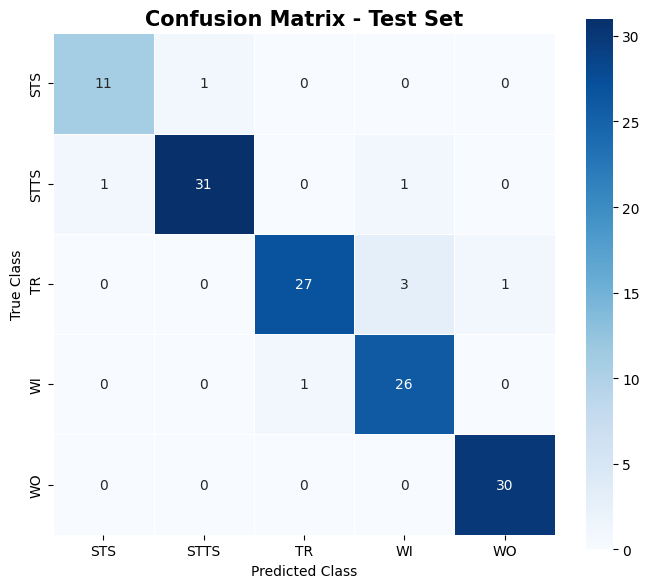

In [ ]:
# ============================================================
# 11. CONFUSION MATRIX TEST SET
# ============================================================

import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

FIGURE_DIR = os.path.join(MODEL_DIR, "Figures")
os.makedirs(FIGURE_DIR, exist_ok=True)

class_names = label_encoder.classes_

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    linewidths=0.5,
    square=True
)

plt.title(
    "Confusion Matrix - Test Set",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "confusion_matrix_test.png"),
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(FIGURE_DIR, "confusion_matrix_test.svg"),
    bbox_inches="tight"
)

plt.show()

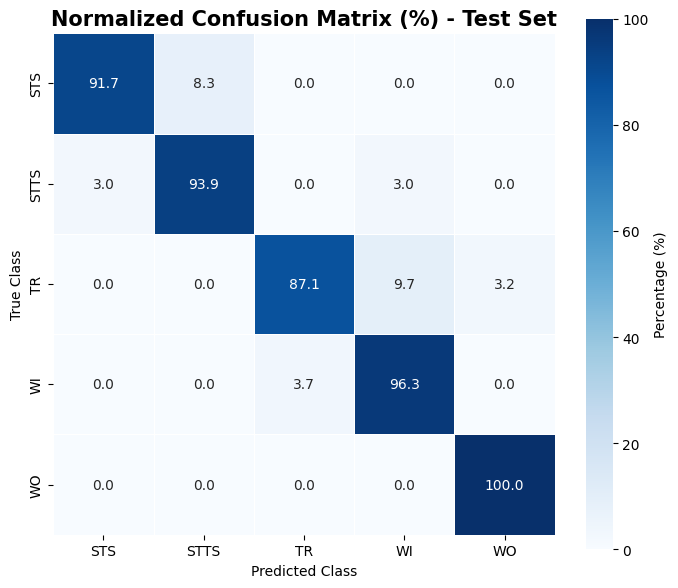

In [ ]:
# ============================================================
# 12. NORMALIZED CONFUSION MATRIX (%)
# ============================================================

import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

FIGURE_DIR = os.path.join(MODEL_DIR, "Figures")
os.makedirs(FIGURE_DIR, exist_ok=True)

class_names = label_encoder.classes_

cm_norm = confusion_matrix(
    y_test,
    y_pred,
    normalize="true"
)

cm_percent = cm_norm * 100

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm_percent,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    linewidths=0.5,
    square=True,
    vmin=0,
    vmax=100
)

plt.title(
    "Normalized Confusion Matrix (%) - Test Set",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")

cbar = plt.gca().collections[0].colorbar
cbar.set_label("Percentage (%)")

plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "normalized_confusion_matrix_test.png"),
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(FIGURE_DIR, "normalized_confusion_matrix_test.svg"),
    bbox_inches="tight"
)

plt.show()

In [ ]:
# ============================================================
# 13. CLASSIFICATION REPORT
# ============================================================

import os
import pandas as pd
from sklearn.metrics import classification_report

REPORT_DIR = os.path.join(MODEL_DIR, "Reports")
os.makedirs(REPORT_DIR, exist_ok=True)

report_dict = classification_report(
    y_test,
    y_pred,
    target_names=label_encoder.classes_,
    output_dict=True,
    digits=4,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).transpose()

display(report_df)

report_path = os.path.join(
    REPORT_DIR,
    "classification_report_test.csv"
)

report_df.to_csv(report_path)

print("Classification report saved to:")
print(report_path)

,precision,recall,f1-score,support
STS,0.916667,0.916667,0.916667,12.00000
STTS,0.968750,0.939394,0.953846,33.00000
TR,0.964286,0.870968,0.915254,31.00000
WI,0.866667,0.962963,0.912281,27.00000
WO,0.967742,1.000000,0.983607,30.00000
accuracy,0.939850,0.939850,0.939850,0.93985
macro avg,0.936822,0.937998,0.936331,133.00000
weighted avg,0.942059,0.939850,0.939771,133.00000


Classification report saved to:
/content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Final_Context_Model/Reports/classification_report_test.csv


Training history saved to:
/content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Final_Context_Model/training_history.csv


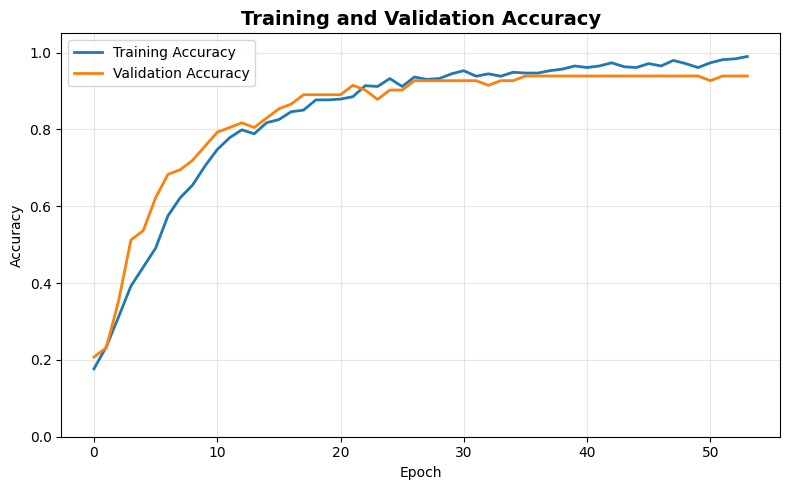

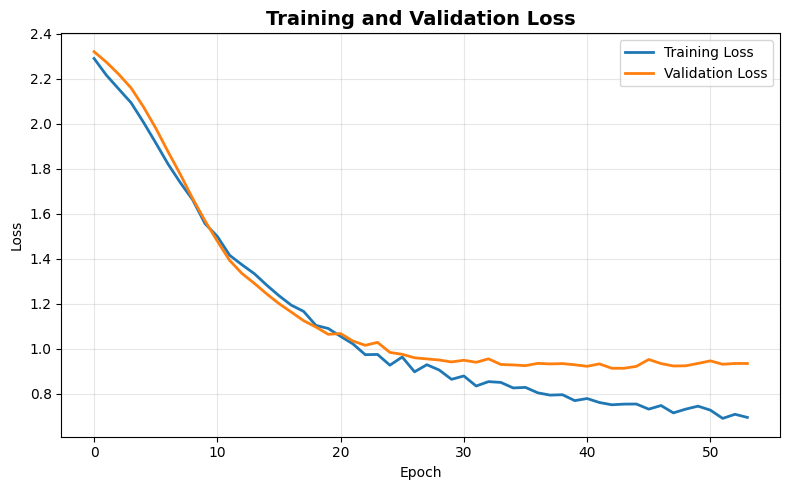

In [ ]:
# ============================================================
# 14. TRAINING ACCURACY AND LOSS CURVE
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

FIGURE_DIR = os.path.join(MODEL_DIR, "Figures")
os.makedirs(FIGURE_DIR, exist_ok=True)

history_df = pd.DataFrame(history.history)

history_csv = os.path.join(
    MODEL_DIR,
    "training_history.csv"
)

history_df.to_csv(history_csv, index=False)

print("Training history saved to:")
print(history_csv)

# Accuracy Curve
plt.figure(figsize=(8, 5))

plt.plot(
    history_df["accuracy"],
    label="Training Accuracy",
    linewidth=2
)

plt.plot(
    history_df["val_accuracy"],
    label="Validation Accuracy",
    linewidth=2
)

plt.title(
    "Training and Validation Accuracy",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "training_validation_accuracy.png"),
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(FIGURE_DIR, "training_validation_accuracy.svg"),
    bbox_inches="tight"
)

plt.show()

# Loss Curve
plt.figure(figsize=(8, 5))

plt.plot(
    history_df["loss"],
    label="Training Loss",
    linewidth=2
)

plt.plot(
    history_df["val_loss"],
    label="Validation Loss",
    linewidth=2
)

plt.title(
    "Training and Validation Loss",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "training_validation_loss.png"),
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(FIGURE_DIR, "training_validation_loss.svg"),
    bbox_inches="tight"
)

plt.show()

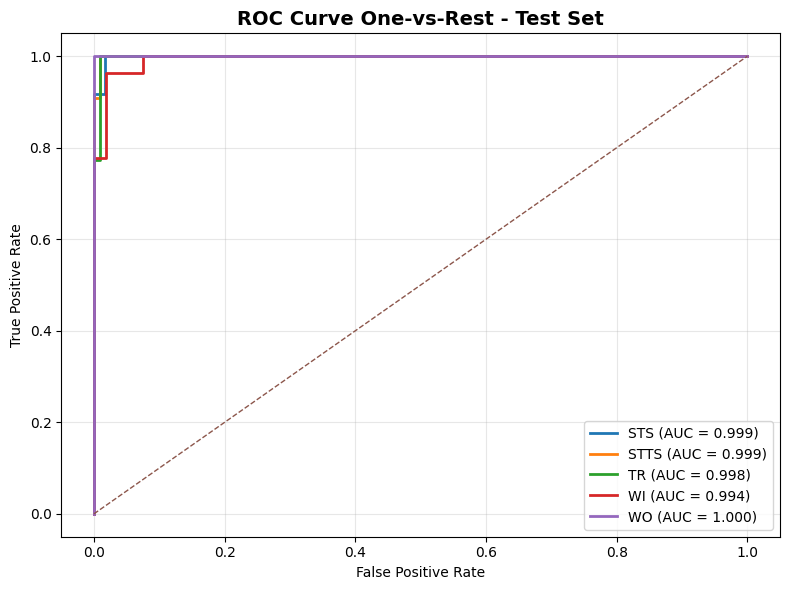

,class,auc
0,STS,0.998623
1,STTS,0.999091
2,TR,0.997786
3,WI,0.993711
4,WO,1.000000


In [ ]:
# ============================================================
# 15. ROC CURVE ONE-vs-REST
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

FIGURE_DIR = os.path.join(MODEL_DIR, "Figures")
os.makedirs(FIGURE_DIR, exist_ok=True)

class_names = label_encoder.classes_
n_classes = len(class_names)

y_test_bin = label_binarize(
    y_test,
    classes=np.arange(n_classes)
)

plt.figure(figsize=(8, 6))

roc_results = []

for i, class_name in enumerate(class_names):

    fpr, tpr, _ = roc_curve(
        y_test_bin[:, i],
        y_pred_prob[:, i]
    )

    roc_auc = auc(fpr, tpr)

    roc_results.append({
        "class": class_name,
        "auc": roc_auc
    })

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{class_name} (AUC = {roc_auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1
)

plt.title(
    "ROC Curve One-vs-Rest - Test Set",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.grid(alpha=0.3)
plt.legend(loc="lower right")

plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "roc_curve_ovr_test.png"),
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(FIGURE_DIR, "roc_curve_ovr_test.svg"),
    bbox_inches="tight"
)

plt.show()

roc_df = pd.DataFrame(roc_results)
display(roc_df)

roc_df.to_csv(
    os.path.join(MODEL_DIR, "roc_auc_test.csv"),
    index=False
)

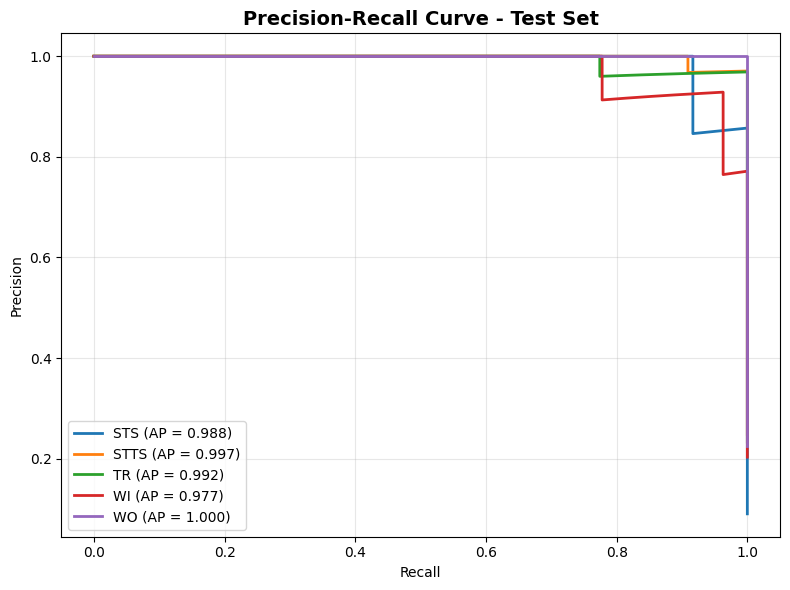

,class,average_precision
0,STS,0.988095
1,STTS,0.997243
2,TR,0.992176
3,WI,0.977247
4,WO,1.000000


In [ ]:
# ============================================================
# 16. PRECISION-RECALL CURVE
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import label_binarize
from sklearn.metrics import precision_recall_curve, average_precision_score

FIGURE_DIR = os.path.join(MODEL_DIR, "Figures")
os.makedirs(FIGURE_DIR, exist_ok=True)

class_names = label_encoder.classes_
n_classes = len(class_names)

y_test_bin = label_binarize(
    y_test,
    classes=np.arange(n_classes)
)

plt.figure(figsize=(8, 6))

pr_results = []

for i, class_name in enumerate(class_names):

    precision, recall, _ = precision_recall_curve(
        y_test_bin[:, i],
        y_pred_prob[:, i]
    )

    ap = average_precision_score(
        y_test_bin[:, i],
        y_pred_prob[:, i]
    )

    pr_results.append({
        "class": class_name,
        "average_precision": ap
    })

    plt.plot(
        recall,
        precision,
        linewidth=2,
        label=f"{class_name} (AP = {ap:.3f})"
    )

plt.title(
    "Precision-Recall Curve - Test Set",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.grid(alpha=0.3)
plt.legend(loc="lower left")

plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "precision_recall_curve_test.png"),
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(FIGURE_DIR, "precision_recall_curve_test.svg"),
    bbox_inches="tight"
)

plt.show()

pr_df = pd.DataFrame(pr_results)
display(pr_df)

pr_df.to_csv(
    os.path.join(MODEL_DIR, "precision_recall_auc_test.csv"),
    index=False
)

,precision,recall,f1-score
STS,0.916667,0.916667,0.916667
STTS,0.968750,0.939394,0.953846
TR,0.964286,0.870968,0.915254
WI,0.866667,0.962963,0.912281
WO,0.967742,1.000000,0.983607


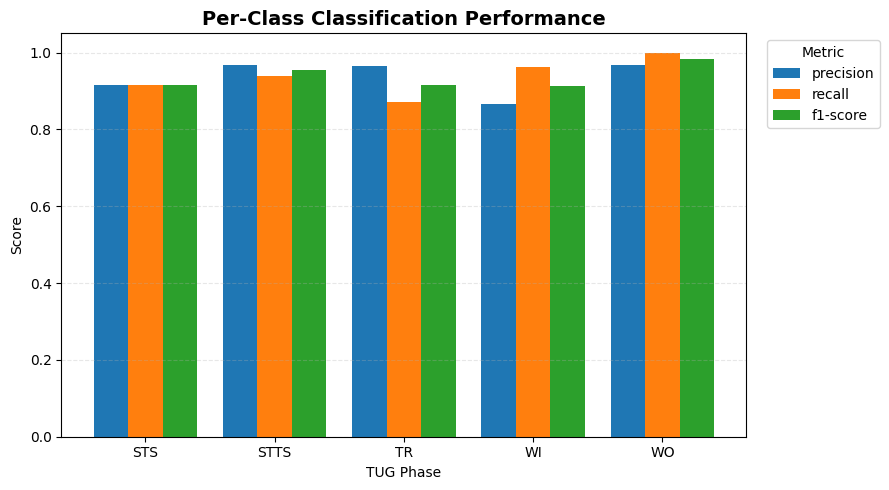

In [ ]:
# ============================================================
# 17. PER-CLASS PERFORMANCE BAR CHART
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

FIGURE_DIR = os.path.join(MODEL_DIR, "Figures")
os.makedirs(FIGURE_DIR, exist_ok=True)

class_report_df = report_df.loc[
    label_encoder.classes_,
    ["precision", "recall", "f1-score"]
]

display(class_report_df)

ax = class_report_df.plot(
    kind="bar",
    figsize=(9, 5),
    width=0.8
)

ax.set_title(
    "Per-Class Classification Performance",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("TUG Phase")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)

ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.xticks(rotation=0)

plt.legend(
    title="Metric",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "per_class_performance.png"),
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(FIGURE_DIR, "per_class_performance.svg"),
    bbox_inches="tight"
)

plt.show()

In [ ]:
# ============================================================
# 18. SAVE FINAL EVALUATION SUMMARY
# ============================================================

import os
import pandas as pd

SUMMARY_DIR = os.path.join(MODEL_DIR, "Summary")
os.makedirs(SUMMARY_DIR, exist_ok=True)

summary_final = pd.DataFrame({
    "metric": [
        "accuracy",
        "precision_macro",
        "recall_macro",
        "f1_macro"
    ],
    "value": [
        test_accuracy,
        test_precision,
        test_recall,
        test_f1
    ]
})

summary_final.to_csv(
    os.path.join(SUMMARY_DIR, "final_test_summary.csv"),
    index=False
)

print("Final summary saved to:")
print(os.path.join(SUMMARY_DIR, "final_test_summary.csv"))

print("\nModel directory:")
print(MODEL_DIR)

Final summary saved to:
/content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Final_Context_Model/Summary/final_test_summary.csv

Model directory:
/content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Final_Context_Model


In [ ]:
# ============================================================
# SKELETON ONLY - 18.A BUILD MODEL
# ============================================================

import tensorflow as tf

from tensorflow.keras.layers import (
    Input, Conv1D, BatchNormalization, MaxPooling1D,
    Bidirectional, LSTM, Dense, Dropout
)

from tensorflow.keras.models import Model
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam


def build_model_skeleton_only():

    skeleton_input = Input(
        shape=(X_train_skeleton.shape[1], X_train_skeleton.shape[2]),
        name="skeleton_input"
    )

    x = Conv1D(
        filters=64,
        kernel_size=3,
        padding="same",
        activation="relu",
        kernel_regularizer=l2(0.001)
    )(skeleton_input)

    x = BatchNormalization()(x)
    x = MaxPooling1D(pool_size=2)(x)

    x = Conv1D(
        filters=128,
        kernel_size=3,
        padding="same",
        activation="relu",
        kernel_regularizer=l2(0.001)
    )(x)

    x = BatchNormalization()(x)

    x = Bidirectional(
        LSTM(
            64,
            return_sequences=False,
            kernel_regularizer=l2(0.001)
        )
    )(x)

    x = Dropout(0.3)(x)

    x = Dense(
        64,
        activation="relu",
        kernel_regularizer=l2(0.001)
    )(x)

    x = Dropout(0.3)(x)

    x = Dense(
        32,
        activation="relu",
        kernel_regularizer=l2(0.001)
    )(x)

    output = Dense(
        len(label_encoder.classes_),
        activation="softmax",
        name="phase_output"
    )(x)

    model = Model(
        inputs=skeleton_input,
        outputs=output
    )

    model.compile(
        optimizer=Adam(learning_rate=LEARNING_RATE),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


skeleton_only_model = build_model_skeleton_only()
skeleton_only_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ skeleton_input (InputLayer)     │ (None, 30, 66)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 30, 64)         │        12,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 30, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 15, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 15, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 15, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ phase_output (Dense)            │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 147,525 (576.27 KB)

 Trainable params: 147,141 (574.77 KB)

 Non-trainable params: 384 (1.50 KB)

In [ ]:
# ============================================================
# SKELETON ONLY - 18.B TRAINING MODEL
# ============================================================

import os
import tensorflow as tf

SKELETON_ONLY_DIR = "/content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Skeleton_Only_Split"
os.makedirs(SKELETON_ONLY_DIR, exist_ok=True)

SKELETON_ONLY_KERAS_PATH = os.path.join(
    SKELETON_ONLY_DIR,
    "skeleton_only_classifier.keras"
)

SKELETON_ONLY_H5_PATH = os.path.join(
    SKELETON_ONLY_DIR,
    "skeleton_only_classifier.h5"
)

tf.keras.backend.clear_session()
skeleton_only_model = build_model_skeleton_only()

callbacks_skeleton_only = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=SKELETON_ONLY_KERAS_PATH,
        monitor="val_loss",
        save_best_only=True,
        save_weights_only=False,
        mode="min",
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    )
]

history_skeleton_only = skeleton_only_model.fit(
    X_train_skeleton,
    y_train,
    validation_data=(X_val_skeleton, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks_skeleton_only,
    class_weight=class_weight,
    verbose=1
)

skeleton_only_model.save(SKELETON_ONLY_H5_PATH)

print("Skeleton-only training selesai.")
print("Model .keras:", SKELETON_ONLY_KERAS_PATH)
print("Model .h5   :", SKELETON_ONLY_H5_PATH)


Epoch 1/300
15/16 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.3076 - loss: 2.2042
Epoch 1: val_loss improved from None to 2.12518, saving model to /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Skeleton_Only_Split/skeleton_only_classifier.keras

Epoch 1: finished saving model to /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Skeleton_Only_Split/skeleton_only_classifier.keras
16/16 ━━━━━━━━━━━━━━━━━━━━ 7s 102ms/step - accuracy: 0.3573 - loss: 2.1739 - val_accuracy: 0.4146 - val_loss: 2.1252 - learning_rate: 1.0000e-04
Epoch 2/300
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.4938 - loss: 2.0211
Epoch 2: val_loss improved from 2.12518 to 2.03488, saving model to /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Skeleton_Only_Split/skeleton_only_classifier.keras

Epoch 2: finished saving model to /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Skeleton_Only_Split/skeleton_only_classifier.keras
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 0.5092 - loss: 2.033

Skeleton-only training selesai.
Model .keras: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Skeleton_Only_Split/skeleton_only_classifier.keras
Model .h5   : /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Skeleton_Only_Split/skeleton_only_classifier.h5


In [ ]:
# ============================================================
# SKELETON ONLY - 18.C TEST EVALUATION
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report
)

best_skeleton_only_model = tf.keras.models.load_model(
    SKELETON_ONLY_KERAS_PATH
)

y_pred_prob_skeleton_only = best_skeleton_only_model.predict(
    X_test_skeleton,
    verbose=0
)

y_pred_skeleton_only = np.argmax(
    y_pred_prob_skeleton_only,
    axis=1
)

skeleton_only_accuracy = accuracy_score(
    y_test,
    y_pred_skeleton_only
)

skeleton_only_precision = precision_score(
    y_test,
    y_pred_skeleton_only,
    average="macro",
    zero_division=0
)

skeleton_only_recall = recall_score(
    y_test,
    y_pred_skeleton_only,
    average="macro",
    zero_division=0
)

skeleton_only_f1 = f1_score(
    y_test,
    y_pred_skeleton_only,
    average="macro",
    zero_division=0
)

print("="*60)
print("SKELETON ONLY TEST EVALUATION")
print("="*60)
print(f"Accuracy  : {skeleton_only_accuracy:.4f}")
print(f"Precision : {skeleton_only_precision:.4f}")
print(f"Recall    : {skeleton_only_recall:.4f}")
print(f"F1-score  : {skeleton_only_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_skeleton_only,
        target_names=label_encoder.classes_,
        digits=4,
        zero_division=0
    )
)

skeleton_only_eval_df = pd.DataFrame({
    "metric": [
        "accuracy",
        "precision_macro",
        "recall_macro",
        "f1_macro"
    ],
    "value": [
        skeleton_only_accuracy,
        skeleton_only_precision,
        skeleton_only_recall,
        skeleton_only_f1
    ]
})

skeleton_only_eval_df.to_csv(
    os.path.join(SKELETON_ONLY_DIR, "skeleton_only_test_evaluation.csv"),
    index=False
)

display(skeleton_only_eval_df)

SKELETON ONLY TEST EVALUATION
Accuracy  : 0.9173
Precision : 0.9115
Recall    : 0.9177
F1-score  : 0.9118

Classification Report:
              precision    recall  f1-score   support

         STS     0.8462    0.9167    0.8800        12
        STTS     0.9118    0.9394    0.9254        33
          TR     1.0000    0.8065    0.8929        31
          WI     0.8621    0.9259    0.8929        27
          WO     0.9375    1.0000    0.9677        30

    accuracy                         0.9173       133
   macro avg     0.9115    0.9177    0.9118       133
weighted avg     0.9221    0.9173    0.9167       133



,metric,value
0,accuracy,0.917293
1,precision_macro,0.911498
2,recall_macro,0.917688
3,f1_macro,0.911766


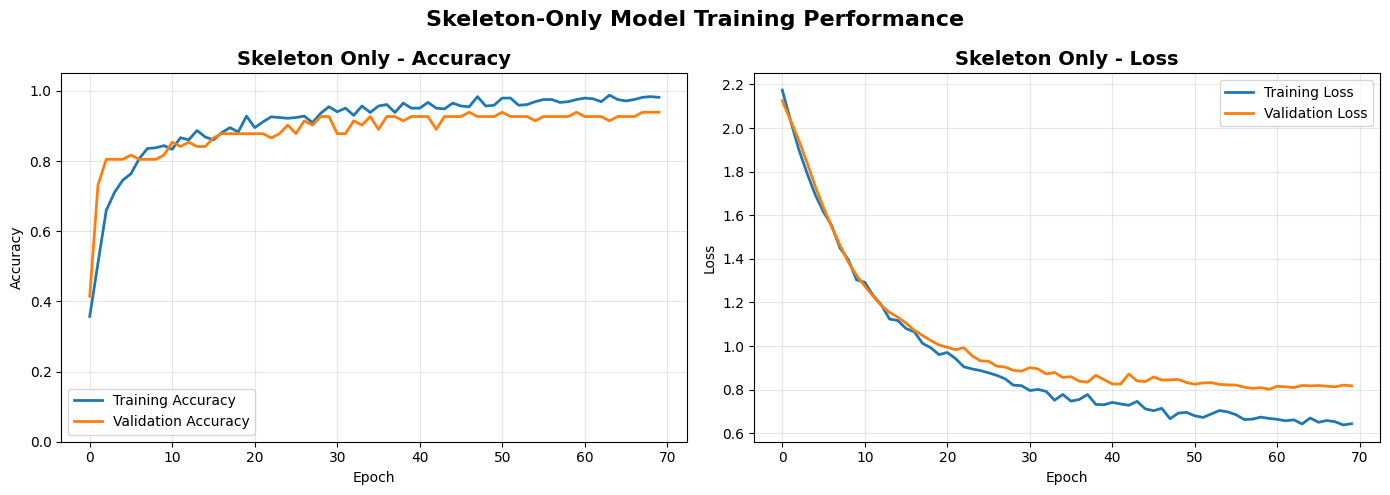

In [ ]:
# ============================================================
# SKELETON ONLY - 18.D ACCURACY AND LOSS CURVE
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

FIGURE_DIR = os.path.join(
    SKELETON_ONLY_DIR,
    "Figures"
)

os.makedirs(FIGURE_DIR, exist_ok=True)

history_skeleton_only_df = pd.DataFrame(
    history_skeleton_only.history
)

history_skeleton_only_df.to_csv(
    os.path.join(
        SKELETON_ONLY_DIR,
        "skeleton_only_training_history.csv"
    ),
    index=False
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

# ------------------------------------------------------------
# Accuracy
# ------------------------------------------------------------
axes[0].plot(
    history_skeleton_only_df["accuracy"],
    label="Training Accuracy",
    linewidth=2
)

axes[0].plot(
    history_skeleton_only_df["val_accuracy"],
    label="Validation Accuracy",
    linewidth=2
)

axes[0].set_title(
    "Skeleton Only - Accuracy",
    fontsize=14,
    fontweight="bold"
)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0, 1.05)
axes[0].grid(alpha=0.3)
axes[0].legend()

# ------------------------------------------------------------
# Loss
# ------------------------------------------------------------
axes[1].plot(
    history_skeleton_only_df["loss"],
    label="Training Loss",
    linewidth=2
)

axes[1].plot(
    history_skeleton_only_df["val_loss"],
    label="Validation Loss",
    linewidth=2
)

axes[1].set_title(
    "Skeleton Only - Loss",
    fontsize=14,
    fontweight="bold"
)

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.suptitle(
    "Skeleton-Only Model Training Performance",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "skeleton_only_accuracy_loss_curve.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "skeleton_only_accuracy_loss_curve.svg"
    ),
    bbox_inches="tight"
)

plt.show()

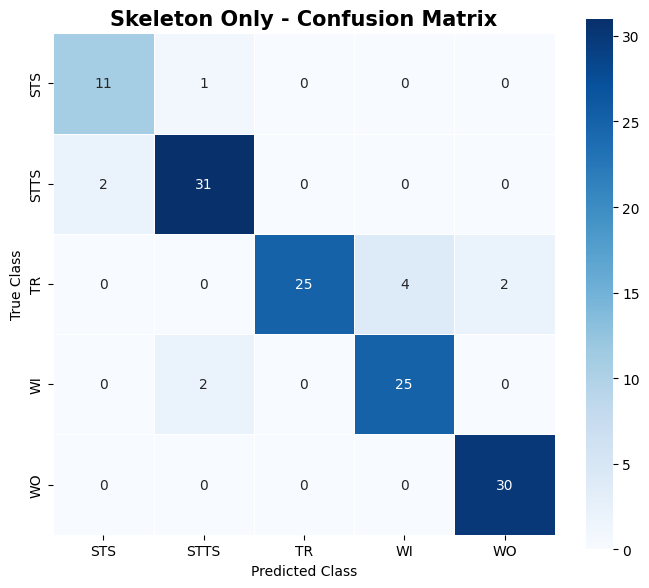

In [ ]:
# ============================================================
# SKELETON ONLY - 8.E CONFUSION MATRIX
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

class_names = label_encoder.classes_

cm_skeleton_only = confusion_matrix(
    y_test,
    y_pred_skeleton_only
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm_skeleton_only,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    linewidths=0.5,
    square=True
)

plt.title(
    "Skeleton Only - Confusion Matrix",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "skeleton_only_confusion_matrix.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "skeleton_only_confusion_matrix.svg"
    ),
    bbox_inches="tight"
)

plt.show()

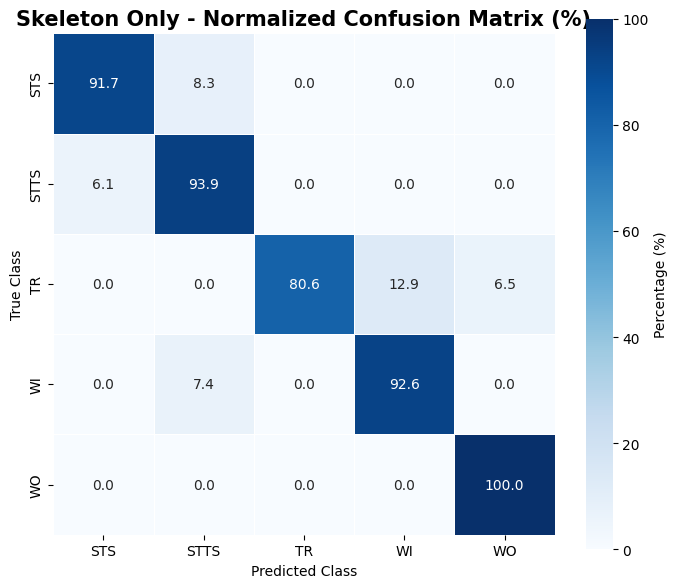

In [ ]:
# ============================================================
# SKELETON ONLY - 8.F NORMALIZED CONFUSION MATRIX (%)
# ============================================================

cm_skeleton_only_norm = confusion_matrix(
    y_test,
    y_pred_skeleton_only,
    normalize="true"
) * 100

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm_skeleton_only_norm,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    linewidths=0.5,
    square=True,
    vmin=0,
    vmax=100
)

plt.title(
    "Skeleton Only - Normalized Confusion Matrix (%)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")

cbar = plt.gca().collections[0].colorbar
cbar.set_label("Percentage (%)")

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "skeleton_only_normalized_confusion_matrix.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "skeleton_only_normalized_confusion_matrix.svg"
    ),
    bbox_inches="tight"
)

plt.show()

In [ ]:
# ============================================================
# SKELETON ONLY - 8.G SAVE CLASSIFICATION REPORT
# ============================================================

from sklearn.metrics import classification_report

skeleton_only_report_dict = classification_report(
    y_test,
    y_pred_skeleton_only,
    target_names=label_encoder.classes_,
    output_dict=True,
    digits=4,
    zero_division=0
)

skeleton_only_report_df = pd.DataFrame(
    skeleton_only_report_dict
).transpose()

display(skeleton_only_report_df)

skeleton_only_report_df.to_csv(
    os.path.join(
        SKELETON_ONLY_DIR,
        "skeleton_only_classification_report.csv"
    )
)

,precision,recall,f1-score,support
STS,0.846154,0.916667,0.880000,12.000000
STTS,0.911765,0.939394,0.925373,33.000000
TR,1.000000,0.806452,0.892857,31.000000
WI,0.862069,0.925926,0.892857,27.000000
WO,0.937500,1.000000,0.967742,30.000000
accuracy,0.917293,0.917293,0.917293,0.917293
macro avg,0.911498,0.917688,0.911766,133.000000
weighted avg,0.922127,0.917293,0.916656,133.000000


In [ ]:
test_accuracy
test_precision
test_recall
test_f1

0.9363308633864783

In [ ]:
# ============================================================
# SKELETON ONLY - 8.H COMPARISON WITH SKELETON + CONTEXT
# ============================================================

comparison_df = pd.DataFrame({
    "model": [
        "Skeleton Only",
        "Skeleton + Context"
    ],
    "accuracy": [
        skeleton_only_accuracy,
        test_accuracy
    ],
    "precision_macro": [
        skeleton_only_precision,
        test_precision
    ],
    "recall_macro": [
        skeleton_only_recall,
        test_recall
    ],
    "f1_macro": [
        skeleton_only_f1,
        test_f1
    ]
})

display(comparison_df)

comparison_df.to_csv(
    os.path.join(
        SKELETON_ONLY_DIR,
        "model_comparison_skeleton_vs_context.csv"
    ),
    index=False
)

,model,accuracy,precision_macro,recall_macro,f1_macro
0,Skeleton Only,0.917293,0.911498,0.917688,0.911766
1,Skeleton + Context,0.939850,0.936822,0.937998,0.936331


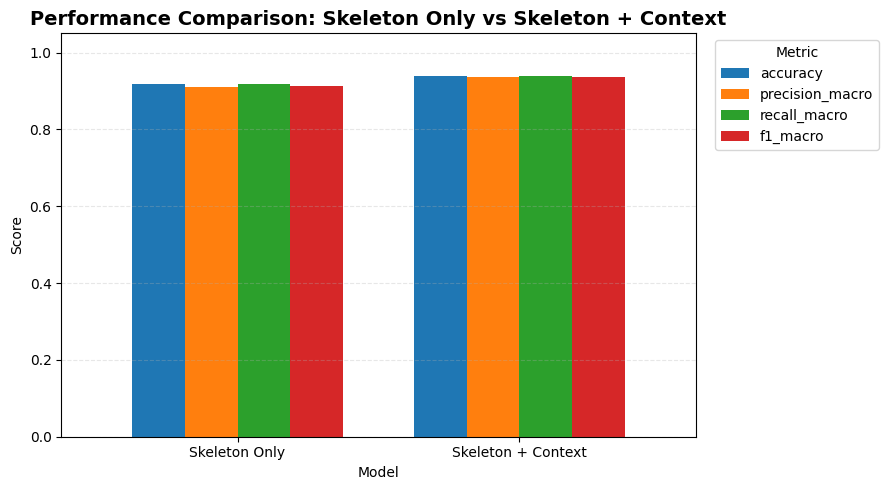

In [ ]:
# ============================================================
# SKELETON ONLY - 8.I MODEL PERFORMANCE COMPARISON
# ============================================================

ax = comparison_df.set_index("model").plot(
    kind="bar",
    figsize=(9, 5),
    width=0.75
)

ax.set_title(
    "Performance Comparison: Skeleton Only vs Skeleton + Context",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.xticks(rotation=0)

plt.legend(
    title="Metric",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "model_comparison_skeleton_vs_context.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "model_comparison_skeleton_vs_context.svg"
    ),
    bbox_inches="tight"
)

plt.show()

In [ ]:
# ============================================================
# STEP 18.J
# TRAINING PERFORMANCE COMPARISON
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

history_context_df = pd.DataFrame(history.history)

history_skeleton_df = pd.DataFrame(
    history_skeleton_only.history
)

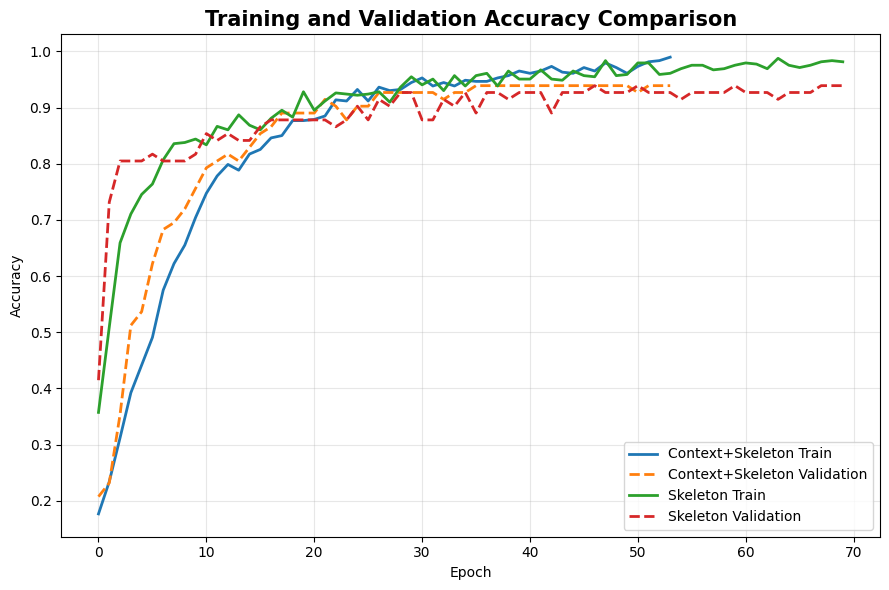

In [ ]:
# ============================================================
# STEP 18.K ACCURACY COMPARISON
# ============================================================

plt.figure(figsize=(9,6))

plt.plot(
    history_context_df["accuracy"],
    linewidth=2,
    label="Context+Skeleton Train"
)

plt.plot(
    history_context_df["val_accuracy"],
    linewidth=2,
    linestyle="--",
    label="Context+Skeleton Validation"
)

plt.plot(
    history_skeleton_df["accuracy"],
    linewidth=2,
    label="Skeleton Train"
)

plt.plot(
    history_skeleton_df["val_accuracy"],
    linewidth=2,
    linestyle="--",
    label="Skeleton Validation"
)

plt.title(
    "Training and Validation Accuracy Comparison",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.grid(alpha=0.3)

plt.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "accuracy_comparison.png"
    ),
    dpi=600
)

plt.show()

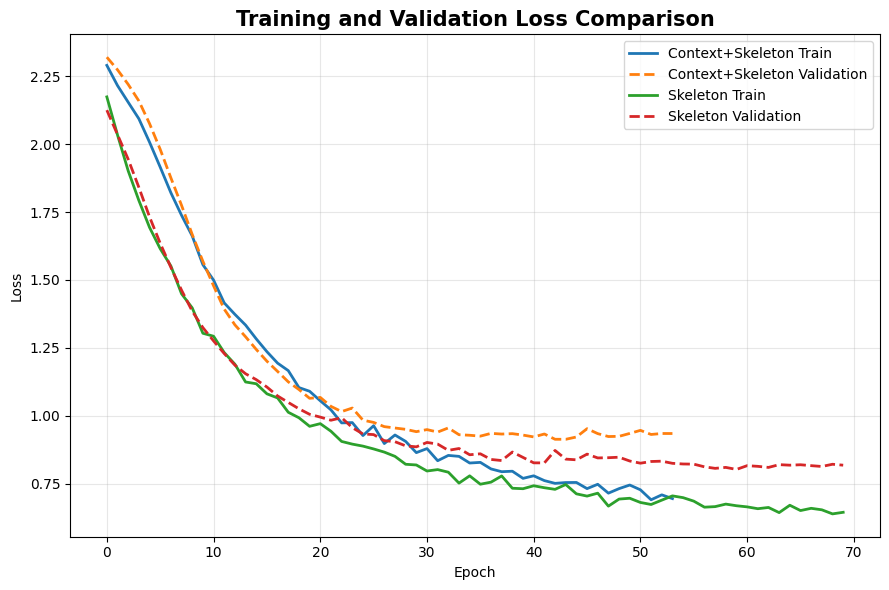

In [ ]:
# ============================================================
# STEP 18.L LOSS COMPARISON
# ============================================================

plt.figure(figsize=(9,6))

plt.plot(
    history_context_df["loss"],
    linewidth=2,
    label="Context+Skeleton Train"
)

plt.plot(
    history_context_df["val_loss"],
    linewidth=2,
    linestyle="--",
    label="Context+Skeleton Validation"
)

plt.plot(
    history_skeleton_df["loss"],
    linewidth=2,
    label="Skeleton Train"
)

plt.plot(
    history_skeleton_df["val_loss"],
    linewidth=2,
    linestyle="--",
    label="Skeleton Validation"
)

plt.title(
    "Training and Validation Loss Comparison",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.grid(alpha=0.3)

plt.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "loss_comparison.png"
    ),
    dpi=600
)

plt.show()

**Tabular Event**

In [ ]:
# ============================================================
# STEP 18. BUILD MODEL: CNN-BiLSTM + ATTENTION FUSION
# ============================================================

import tensorflow as tf

from tensorflow.keras.layers import (
    Input,
    Conv1D,
    BatchNormalization,
    MaxPooling1D,
    Bidirectional,
    LSTM,
    Dense,
    Dropout,
    Concatenate,
    Multiply
)

from tensorflow.keras.models import Model
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam


def build_model_attention_fusion():

    # ========================================================
    # SKELETON BRANCH
    # ========================================================
    skeleton_input = Input(
        shape=(X_train_skeleton.shape[1], X_train_skeleton.shape[2]),
        name="skeleton_input"
    )

    x = Conv1D(
        filters=64,
        kernel_size=3,
        padding="same",
        activation="relu",
        kernel_regularizer=l2(0.001)
    )(skeleton_input)

    x = BatchNormalization()(x)
    x = MaxPooling1D(pool_size=2)(x)

    x = Conv1D(
        filters=128,
        kernel_size=3,
        padding="same",
        activation="relu",
        kernel_regularizer=l2(0.001)
    )(x)

    x = BatchNormalization()(x)

    x = Bidirectional(
        LSTM(
            64,
            return_sequences=False,
            kernel_regularizer=l2(0.001)
        )
    )(x)

    x = Dropout(0.3)(x)

    skeleton_feature = Dense(
        64,
        activation="relu",
        kernel_regularizer=l2(0.001),
        name="skeleton_feature"
    )(x)

    # ========================================================
    # CONTEXT BRANCH
    # ========================================================
    context_input = Input(
        shape=(X_train_context.shape[1],),
        name="context_input"
    )

    context_feature = Dense(
        32,
        activation="relu",
        kernel_regularizer=l2(0.001),
        name="context_feature"
    )(context_input)

    context_feature = Dropout(0.2)(context_feature)

    # ========================================================
    # ATTENTION FUSION
    # Context menghasilkan bobot perhatian untuk skeleton feature
    # ========================================================
    attention_weight = Dense(
        64,
        activation="sigmoid",
        name="attention_weight"
    )(context_feature)

    attended_skeleton = Multiply(
        name="attended_skeleton"
    )([
        skeleton_feature,
        attention_weight
    ])

    fusion = Concatenate(
        name="attention_fusion"
    )([
        attended_skeleton,
        context_feature
    ])

    # ========================================================
    # CLASSIFIER
    # ========================================================
    z = Dense(
        64,
        activation="relu",
        kernel_regularizer=l2(0.001)
    )(fusion)

    z = Dropout(0.3)(z)

    z = Dense(
        32,
        activation="relu",
        kernel_regularizer=l2(0.001)
    )(z)

    output = Dense(
        len(label_encoder.classes_),
        activation="softmax",
        name="phase_output"
    )(z)

    model = Model(
        inputs=[skeleton_input, context_input],
        outputs=output
    )

    model.compile(
        optimizer=Adam(learning_rate=LEARNING_RATE),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


# Cek model
attention_model = build_model_attention_fusion()
attention_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ skeleton_input      │ (None, 30, 66)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 30, 64)    │     12,736 │ skeleton_input[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 30, 64)    │        256 │ conv1d_2[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_1     │ (None, 15, 64)    │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 15, 128)   │     24,704 │ max_pooling1d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 15, 128)   │        512 │ conv1d_3[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ context_input       │ (None, 4)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_1     │ (None, 128)       │     98,816 │ batch_normalizat… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ context_feature     │ (None, 32)        │        160 │ context_input[0]… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 128)       │          0 │ bidirectional_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 32)        │          0 │ context_feature[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ skeleton_feature    │ (None, 64)        │      8,256 │ dropout_2[0][0]   │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_weight    │ (None, 64)        │      2,112 │ dropout_3[0][0]   │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attended_skeleton   │ (None, 64)        │          0 │ skeleton_feature… │
│ (Multiply)          │                   │            │ attention_weight… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_fusion    │ (None, 96)        │          0 │ attended_skeleto… │
│ (Concatenate)       │                   │            │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 64)        │      6,208 │ attention_fusion… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 64)        │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 32)        │      2,080 │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ phase_output        │ (None, 5)         │        165 │ dense_3[0][0]     │
│ (Dense)             │                   │            │                 

 Total params: 156,005 (609.39 KB)

 Trainable params: 155,621 (607.89 KB)

 Non-trainable params: 384 (1.50 KB)

In [ ]:
# ============================================================
# STEP 19. TRAINING ATTENTION FUSION MODEL
# ============================================================

import os
import tensorflow as tf

ATTENTION_DIR = "/content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Attention_Fusion_Model"
os.makedirs(ATTENTION_DIR, exist_ok=True)

ATTENTION_KERAS_PATH = os.path.join(
    ATTENTION_DIR,
    "attention_fusion_classifier.keras"
)

ATTENTION_H5_PATH = os.path.join(
    ATTENTION_DIR,
    "attention_fusion_classifier.h5"
)

tf.keras.backend.clear_session()

attention_model = build_model_attention_fusion()

callbacks_attention = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=ATTENTION_KERAS_PATH,
        monitor="val_loss",
        save_best_only=True,
        save_weights_only=False,
        mode="min",
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    )
]

history_attention = attention_model.fit(
    [X_train_skeleton, X_train_context],
    y_train,
    validation_data=(
        [X_val_skeleton, X_val_context],
        y_val
    ),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks_attention,
    class_weight=class_weight,
    verbose=1
)

attention_model.save(ATTENTION_H5_PATH)

print("Attention Fusion training selesai.")
print("Model .keras:", ATTENTION_KERAS_PATH)
print("Model .h5   :", ATTENTION_H5_PATH)


Epoch 1/300
15/16 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.0961 - loss: 2.3239
Epoch 1: val_loss improved from None to 2.35988, saving model to /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Attention_Fusion_Model/attention_fusion_classifier.keras

Epoch 1: finished saving model to /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Attention_Fusion_Model/attention_fusion_classifier.keras
16/16 ━━━━━━━━━━━━━━━━━━━━ 9s 168ms/step - accuracy: 0.1068 - loss: 2.3232 - val_accuracy: 0.0244 - val_loss: 2.3599 - learning_rate: 1.0000e-04
Epoch 2/300
14/16 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.1043 - loss: 2.2824
Epoch 2: val_loss improved from 2.35988 to 2.33857, saving model to /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Attention_Fusion_Model/attention_fusion_classifier.keras

Epoch 2: finished saving model to /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Attention_Fusion_Model/attention_fusion_classifier.keras
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 39ms/step - accura

Attention Fusion training selesai.
Model .keras: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Attention_Fusion_Model/attention_fusion_classifier.keras
Model .h5   : /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Attention_Fusion_Model/attention_fusion_classifier.h5


In [ ]:
# ============================================================
# STEP 20. EVALUATION ATTENTION FUSION MODEL
# ============================================================

import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

best_attention_model = tf.keras.models.load_model(
    ATTENTION_KERAS_PATH
)

y_pred_prob_attention = best_attention_model.predict(
    [X_test_skeleton, X_test_context],
    verbose=0
)

y_pred_attention = np.argmax(
    y_pred_prob_attention,
    axis=1
)

attention_accuracy = accuracy_score(
    y_test,
    y_pred_attention
)

attention_precision = precision_score(
    y_test,
    y_pred_attention,
    average="macro",
    zero_division=0
)

attention_recall = recall_score(
    y_test,
    y_pred_attention,
    average="macro",
    zero_division=0
)

attention_f1 = f1_score(
    y_test,
    y_pred_attention,
    average="macro",
    zero_division=0
)

print("="*60)
print("ATTENTION FUSION TEST EVALUATION")
print("="*60)

print(f"Accuracy  : {attention_accuracy:.4f}")
print(f"Precision : {attention_precision:.4f}")
print(f"Recall    : {attention_recall:.4f}")
print(f"F1-score  : {attention_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_attention,
        target_names=label_encoder.classes_,
        digits=4,
        zero_division=0
    )
)

attention_eval_df = pd.DataFrame({
    "metric": [
        "accuracy",
        "precision_macro",
        "recall_macro",
        "f1_macro"
    ],
    "value": [
        attention_accuracy,
        attention_precision,
        attention_recall,
        attention_f1
    ]
})

attention_eval_df.to_csv(
    os.path.join(
        ATTENTION_DIR,
        "attention_fusion_test_evaluation.csv"
    ),
    index=False
)

display(attention_eval_df)

ATTENTION FUSION TEST EVALUATION
Accuracy  : 0.9474
Precision : 0.9517
Recall    : 0.9520
F1-score  : 0.9515

Classification Report:
              precision    recall  f1-score   support

         STS     1.0000    1.0000    1.0000        12
        STTS     0.9706    1.0000    0.9851        33
          TR     0.9310    0.8710    0.9000        31
          WI     0.8889    0.8889    0.8889        27
          WO     0.9677    1.0000    0.9836        30

    accuracy                         0.9474       133
   macro avg     0.9517    0.9520    0.9515       133
weighted avg     0.9468    0.9474    0.9467       133



,metric,value
0,accuracy,0.947368
1,precision_macro,0.951651
2,recall_macro,0.951971
3,f1_macro,0.951514


In [ ]:
history
history_skeleton_only
history_attention

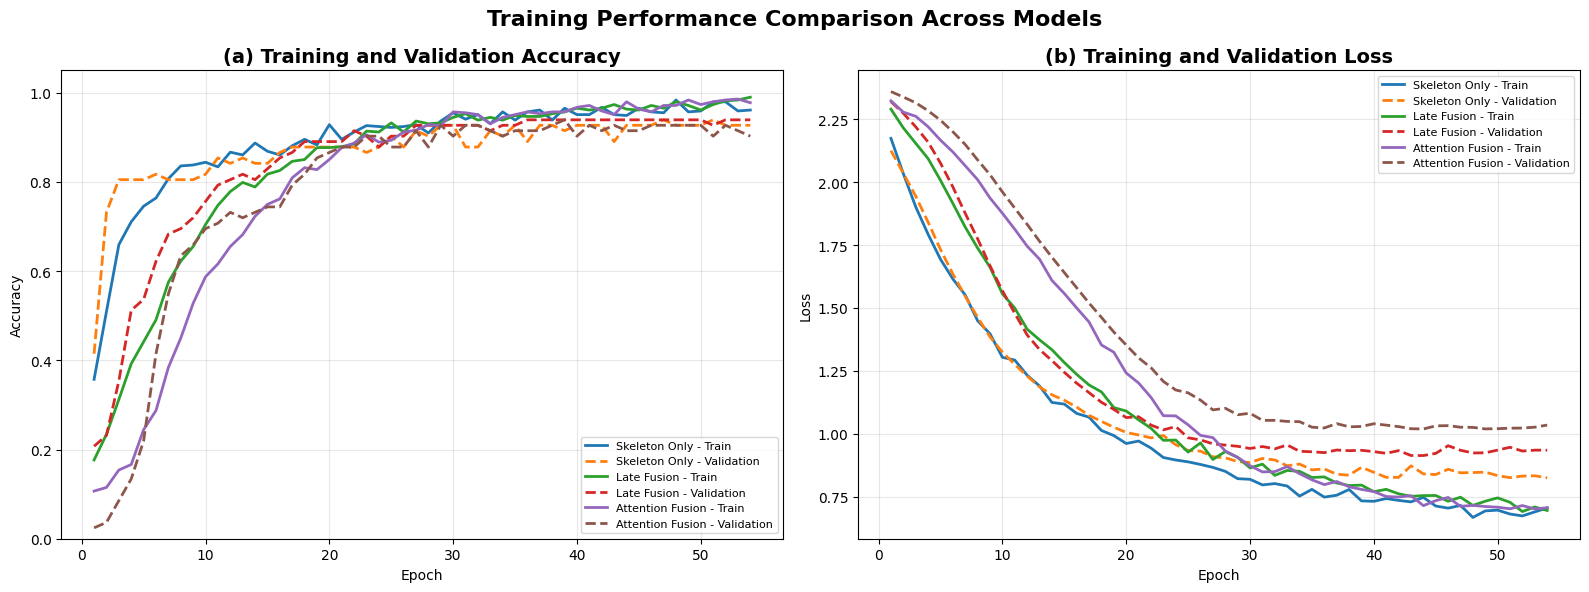

In [ ]:
# ============================================================
# STEP 21. TRAINING PERFORMANCE COMPARISON
# Skeleton Only vs Late Fusion vs Attention Fusion
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# Folder penyimpanan
# ============================================================

COMPARE_DIR = "/content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Model_Comparison"
os.makedirs(COMPARE_DIR, exist_ok=True)

# ============================================================
# Ambil history dari masing-masing model
# ============================================================

history_late_df = pd.DataFrame(history.history)
history_skeleton_df = pd.DataFrame(history_skeleton_only.history)
history_attention_df = pd.DataFrame(history_attention.history)

# ============================================================
# Samakan panjang epoch
# Jika EarlyStopping membuat epoch berbeda
# ============================================================

min_epochs = min(
    len(history_late_df),
    len(history_skeleton_df),
    len(history_attention_df)
)

history_late_df = history_late_df.iloc[:min_epochs]
history_skeleton_df = history_skeleton_df.iloc[:min_epochs]
history_attention_df = history_attention_df.iloc[:min_epochs]

epochs = range(1, min_epochs + 1)

# ============================================================
# Plot Accuracy dan Loss dalam satu figure
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 6)
)

# ------------------------------------------------------------
# Accuracy comparison
# ------------------------------------------------------------

axes[0].plot(
    epochs,
    history_skeleton_df["accuracy"],
    linewidth=2,
    label="Skeleton Only - Train"
)

axes[0].plot(
    epochs,
    history_skeleton_df["val_accuracy"],
    linewidth=2,
    linestyle="--",
    label="Skeleton Only - Validation"
)

axes[0].plot(
    epochs,
    history_late_df["accuracy"],
    linewidth=2,
    label="Late Fusion - Train"
)

axes[0].plot(
    epochs,
    history_late_df["val_accuracy"],
    linewidth=2,
    linestyle="--",
    label="Late Fusion - Validation"
)

axes[0].plot(
    epochs,
    history_attention_df["accuracy"],
    linewidth=2,
    label="Attention Fusion - Train"
)

axes[0].plot(
    epochs,
    history_attention_df["val_accuracy"],
    linewidth=2,
    linestyle="--",
    label="Attention Fusion - Validation"
)

axes[0].set_title(
    "(a) Training and Validation Accuracy",
    fontsize=14,
    fontweight="bold"
)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0, 1.05)
axes[0].grid(alpha=0.3)
axes[0].legend(fontsize=8)

# ------------------------------------------------------------
# Loss comparison
# ------------------------------------------------------------

axes[1].plot(
    epochs,
    history_skeleton_df["loss"],
    linewidth=2,
    label="Skeleton Only - Train"
)

axes[1].plot(
    epochs,
    history_skeleton_df["val_loss"],
    linewidth=2,
    linestyle="--",
    label="Skeleton Only - Validation"
)

axes[1].plot(
    epochs,
    history_late_df["loss"],
    linewidth=2,
    label="Late Fusion - Train"
)

axes[1].plot(
    epochs,
    history_late_df["val_loss"],
    linewidth=2,
    linestyle="--",
    label="Late Fusion - Validation"
)

axes[1].plot(
    epochs,
    history_attention_df["loss"],
    linewidth=2,
    label="Attention Fusion - Train"
)

axes[1].plot(
    epochs,
    history_attention_df["val_loss"],
    linewidth=2,
    linestyle="--",
    label="Attention Fusion - Validation"
)

axes[1].set_title(
    "(b) Training and Validation Loss",
    fontsize=14,
    fontweight="bold"
)

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=8)

# ============================================================
# Final layout
# ============================================================

plt.suptitle(
    "Training Performance Comparison Across Models",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        COMPARE_DIR,
        "training_performance_comparison_3models.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(
        COMPARE_DIR,
        "training_performance_comparison_3models.svg"
    ),
    bbox_inches="tight"
)

plt.show()

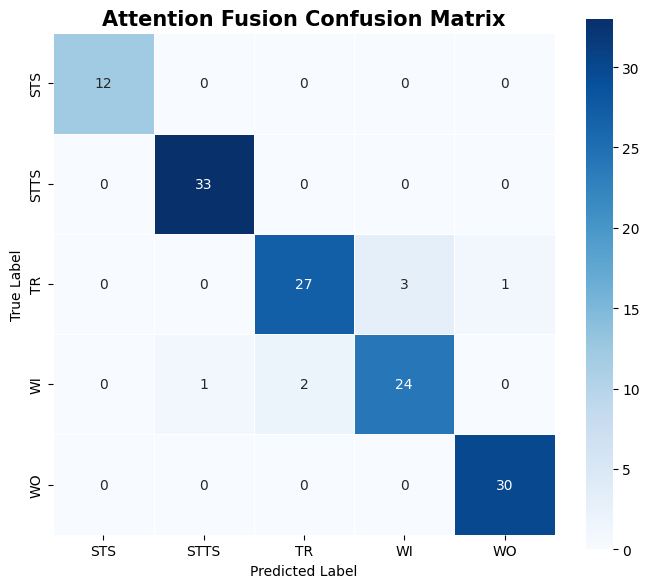

In [ ]:
# ============================================================
# STEP 22. CONFUSION MATRIX
# ============================================================

import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

FIGURE_DIR = os.path.join(
    ATTENTION_DIR,
    "Figures"
)

os.makedirs(FIGURE_DIR, exist_ok=True)

class_names = label_encoder.classes_

cm_attention = confusion_matrix(
    y_test,
    y_pred_attention
)

plt.figure(figsize=(7,6))

sns.heatmap(
    cm_attention,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    linewidths=0.5,
    square=True
)

plt.title(
    "Attention Fusion Confusion Matrix",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "attention_confusion_matrix.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

plt.show()

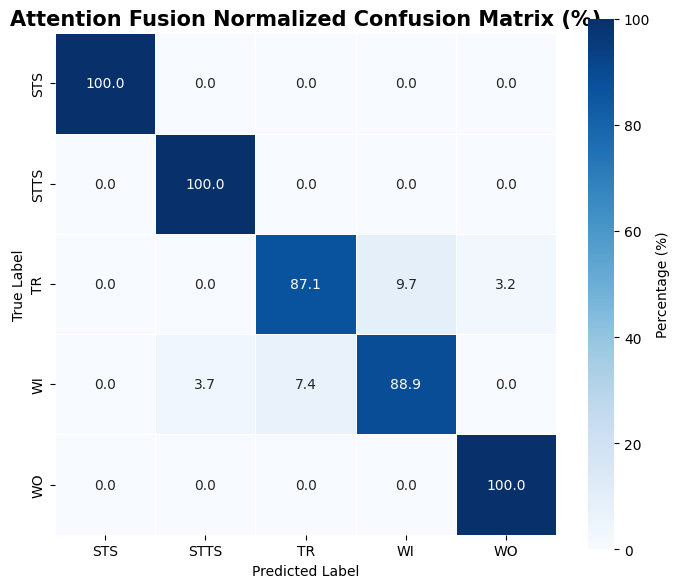

In [ ]:
# ============================================================
# STEP 23. NORMALIZED CONFUSION MATRIX
# ============================================================

cm_attention_norm = confusion_matrix(
    y_test,
    y_pred_attention,
    normalize="true"
) * 100

plt.figure(figsize=(7,6))

sns.heatmap(
    cm_attention_norm,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    linewidths=0.5,
    square=True,
    vmin=0,
    vmax=100
)

plt.title(
    "Attention Fusion Normalized Confusion Matrix (%)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

cbar = plt.gca().collections[0].colorbar
cbar.set_label("Percentage (%)")

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "attention_normalized_confusion_matrix.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

plt.show()

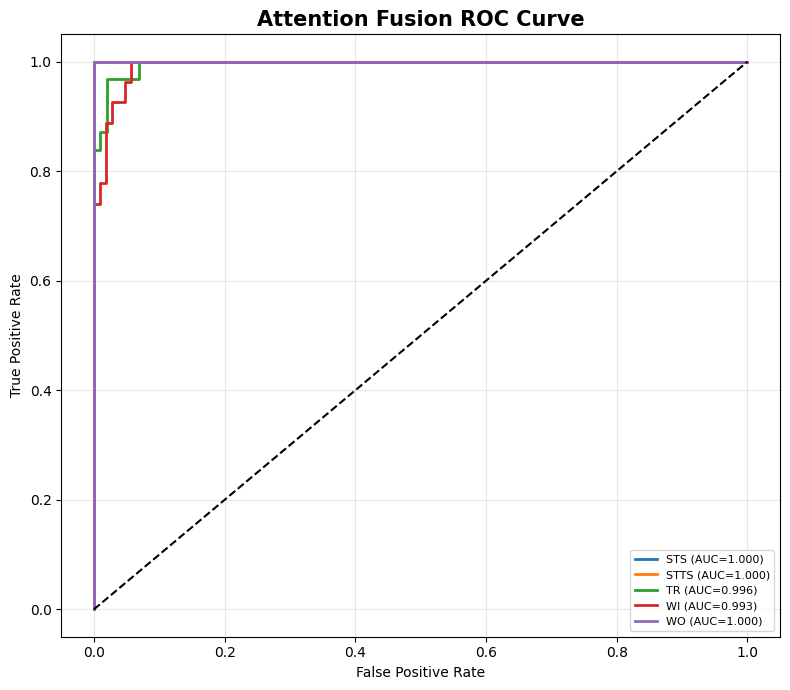

In [ ]:
# ============================================================
# STEP 24. MULTI-CLASS ROC CURVE
# ============================================================

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

n_classes = len(label_encoder.classes_)

y_test_bin = label_binarize(
    y_test,
    classes=np.arange(n_classes)
)

plt.figure(figsize=(8,7))

for i in range(n_classes):

    fpr, tpr, _ = roc_curve(
        y_test_bin[:, i],
        y_pred_prob_attention[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{label_encoder.classes_[i]} (AUC={roc_auc:.3f})"
    )

plt.plot(
    [0,1],
    [0,1],
    'k--'
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "Attention Fusion ROC Curve",
    fontsize=15,
    fontweight="bold"
)

plt.legend(
    loc="lower right",
    fontsize=8
)

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "attention_ROC_curve.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

plt.show()

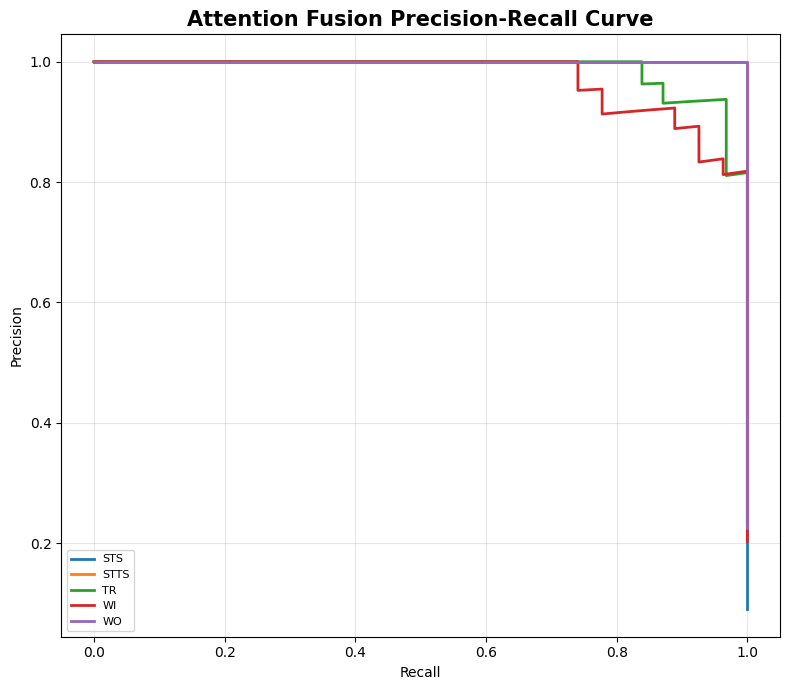

In [ ]:
# ============================================================
# STEP 25. PRECISION-RECALL CURVE
# ============================================================

from sklearn.metrics import precision_recall_curve

plt.figure(figsize=(8,7))

for i in range(n_classes):

    precision, recall, _ = precision_recall_curve(
        y_test_bin[:, i],
        y_pred_prob_attention[:, i]
    )

    plt.plot(
        recall,
        precision,
        linewidth=2,
        label=label_encoder.classes_[i]
    )

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title(
    "Attention Fusion Precision-Recall Curve",
    fontsize=15,
    fontweight="bold"
)

plt.legend(fontsize=8)

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "attention_precision_recall_curve.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [ ]:
y_test

y_pred_skeleton_only
y_pred
y_pred_attention

y_pred_prob_skeleton_only
y_pred_prob
y_pred_prob_attention

label_encoder

LabelEncoder()

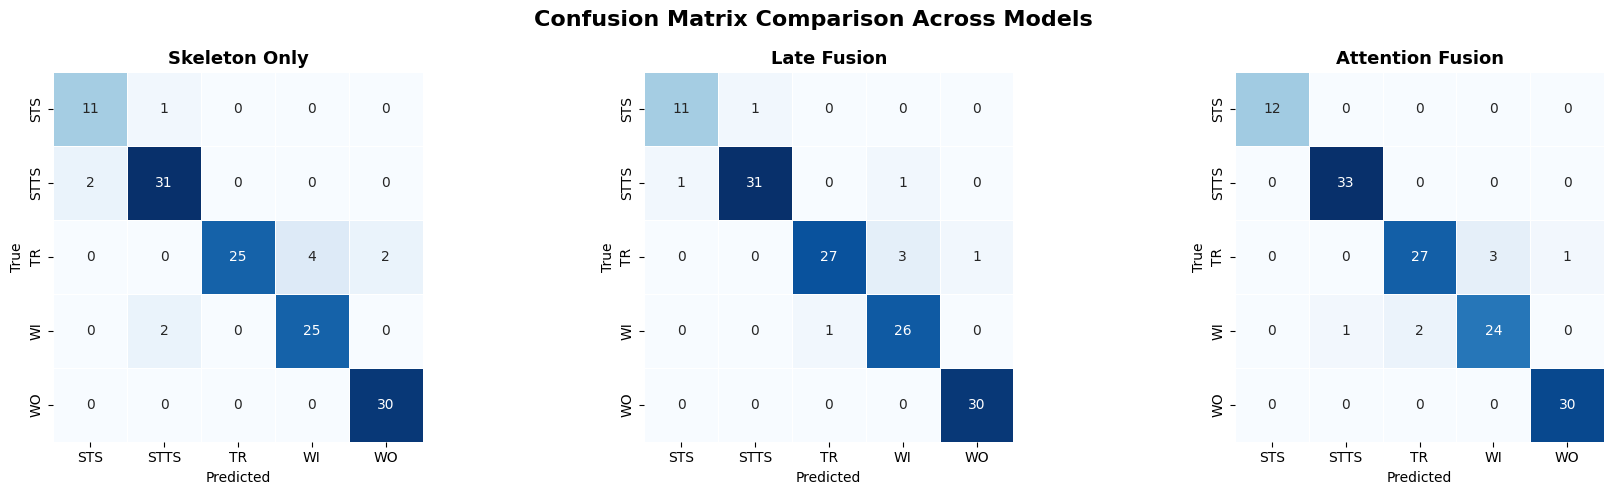

In [ ]:
# ============================================================
# STEP 26. CONFUSION MATRIX COMPARISON - 3 MODELS
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

COMPARE_DIR = "/content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Model_Comparison"
os.makedirs(COMPARE_DIR, exist_ok=True)

class_names = label_encoder.classes_

models_cm = {
    "Skeleton Only": y_pred_skeleton_only,
    "Late Fusion": y_pred,
    "Attention Fusion": y_pred_attention
}

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5)
)

for ax, (model_name, y_pred_model) in zip(axes, models_cm.items()):

    cm = confusion_matrix(
        y_test,
        y_pred_model
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        linewidths=0.5,
        square=True,
        cbar=False,
        ax=ax
    )

    ax.set_title(
        model_name,
        fontsize=13,
        fontweight="bold"
    )

    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")

plt.suptitle(
    "Confusion Matrix Comparison Across Models",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        COMPARE_DIR,
        "confusion_matrix_comparison_3models.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(
        COMPARE_DIR,
        "confusion_matrix_comparison_3models.svg"
    ),
    bbox_inches="tight"
)

plt.show()

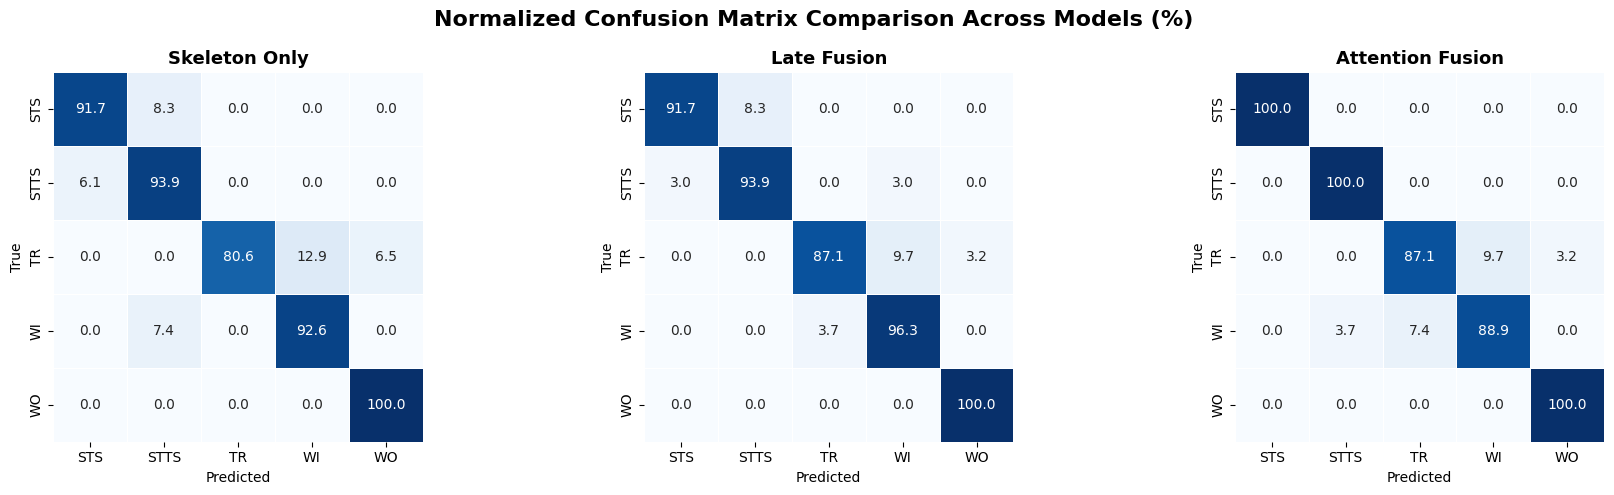

In [ ]:
# ============================================================
# STEP 27. NORMALIZED CONFUSION MATRIX COMPARISON - 3 MODELS
# ============================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5)
)

for ax, (model_name, y_pred_model) in zip(axes, models_cm.items()):

    cm_norm = confusion_matrix(
        y_test,
        y_pred_model,
        normalize="true"
    ) * 100

    sns.heatmap(
        cm_norm,
        annot=True,
        fmt=".1f",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        linewidths=0.5,
        square=True,
        vmin=0,
        vmax=100,
        cbar=False,
        ax=ax
    )

    ax.set_title(
        model_name,
        fontsize=13,
        fontweight="bold"
    )

    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")

plt.suptitle(
    "Normalized Confusion Matrix Comparison Across Models (%)",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        COMPARE_DIR,
        "normalized_confusion_matrix_comparison_3models.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(
        COMPARE_DIR,
        "normalized_confusion_matrix_comparison_3models.svg"
    ),
    bbox_inches="tight"
)

plt.show()

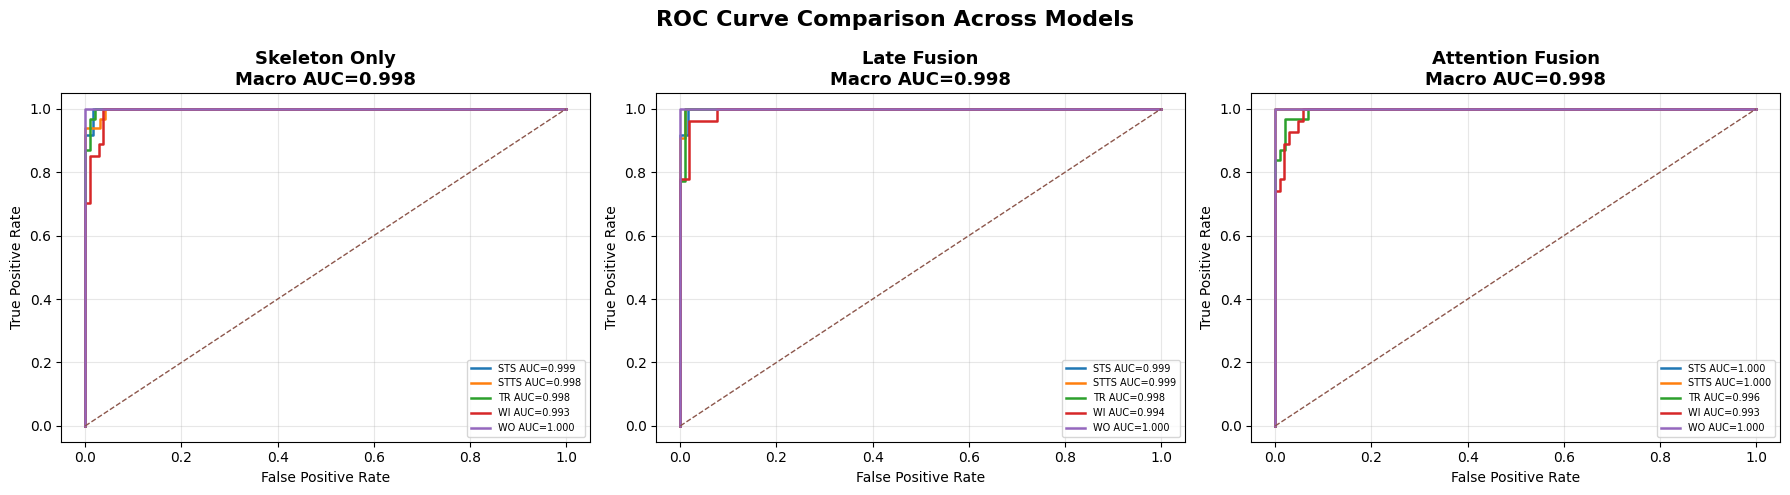

,model,class,auc
0,Skeleton Only,STS,0.998623
1,Skeleton Only,STTS,0.997879
2,Skeleton Only,TR,0.998419
3,Skeleton Only,WI,0.993361
4,Skeleton Only,WO,1.000000
5,Late Fusion,STS,0.998623
6,Late Fusion,STTS,0.999091
7,Late Fusion,TR,0.997786
8,Late Fusion,WI,0.993711
9,Late Fusion,WO,1.000000


In [ ]:
# ============================================================
# STEP 28. ROC CURVE COMPARISON - 3 MODELS
# ============================================================

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

n_classes = len(label_encoder.classes_)

y_test_bin = label_binarize(
    y_test,
    classes=np.arange(n_classes)
)

models_prob = {
    "Skeleton Only": y_pred_prob_skeleton_only,
    "Late Fusion": y_pred_prob,
    "Attention Fusion": y_pred_prob_attention
}

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5)
)

roc_summary_records = []

for ax, (model_name, y_prob_model) in zip(axes, models_prob.items()):

    auc_values = []

    for i in range(n_classes):

        fpr, tpr, _ = roc_curve(
            y_test_bin[:, i],
            y_prob_model[:, i]
        )

        roc_auc = auc(fpr, tpr)
        auc_values.append(roc_auc)

        ax.plot(
            fpr,
            tpr,
            linewidth=1.8,
            label=f"{class_names[i]} AUC={roc_auc:.3f}"
        )

        roc_summary_records.append({
            "model": model_name,
            "class": class_names[i],
            "auc": roc_auc
        })

    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        linewidth=1
    )

    ax.set_title(
        f"{model_name}\nMacro AUC={np.mean(auc_values):.3f}",
        fontsize=13,
        fontweight="bold"
    )

    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7, loc="lower right")

plt.suptitle(
    "ROC Curve Comparison Across Models",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        COMPARE_DIR,
        "roc_curve_comparison_3models.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(
        COMPARE_DIR,
        "roc_curve_comparison_3models.svg"
    ),
    bbox_inches="tight"
)

plt.show()

roc_summary_df = pd.DataFrame(roc_summary_records)

roc_summary_df.to_csv(
    os.path.join(
        COMPARE_DIR,
        "roc_auc_comparison_3models.csv"
    ),
    index=False
)

display(roc_summary_df)

In [ ]:
# ============================================================
# STEP 29. FINAL METRIC COMPARISON TABLE
# ============================================================

comparison_3models_df = pd.DataFrame({
    "model": [
        "Skeleton Only",
        "Late Fusion",
        "Attention Fusion"
    ],
    "accuracy": [
        skeleton_only_accuracy,
        test_accuracy,
        attention_accuracy
    ],
    "precision_macro": [
        skeleton_only_precision,
        test_precision,
        attention_precision
    ],
    "recall_macro": [
        skeleton_only_recall,
        test_recall,
        attention_recall
    ],
    "f1_macro": [
        skeleton_only_f1,
        test_f1,
        attention_f1
    ]
})

display(comparison_3models_df)

comparison_3models_df.to_csv(
    os.path.join(
        COMPARE_DIR,
        "final_metric_comparison_3models.csv"
    ),
    index=False
)

,model,accuracy,precision_macro,recall_macro,f1_macro
0,Skeleton Only,0.917293,0.911498,0.917688,0.911766
1,Late Fusion,0.939850,0.936822,0.937998,0.936331
2,Attention Fusion,0.947368,0.951651,0.951971,0.951514


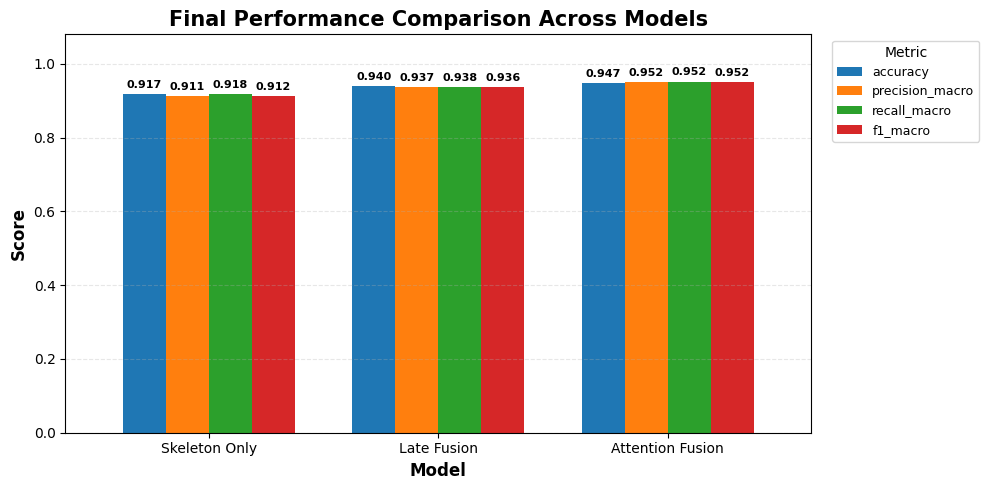

In [ ]:
# ============================================================
# STEP 30. FINAL METRIC COMPARISON BAR CHART
# ============================================================

ax = comparison_3models_df.set_index("model").plot(
    kind="bar",
    figsize=(10, 5),
    width=0.75
)

ax.set_title(
    "Final Performance Comparison Across Models",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel(
    "Model",
    fontsize=12,
    fontweight="bold"
)

ax.set_ylabel(
    "Score",
    fontsize=12,
    fontweight="bold"
)

# Beri ruang di atas bar agar label tidak terpotong
ax.set_ylim(0, 1.08)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.xticks(
    rotation=0,
    fontsize=10
)

plt.yticks(fontsize=10)

# ============================================================
# Tambahkan nilai di atas setiap bar
# ============================================================
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",          # tampilkan 3 digit desimal
        label_type="edge",
        padding=3,
        fontsize=8,
        fontweight="bold",
        rotation=0
    )

plt.legend(
    title="Metric",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=9,
    title_fontsize=10
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        COMPARE_DIR,
        "final_metric_comparison_3models.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(
        COMPARE_DIR,
        "final_metric_comparison_3models.svg"
    ),
    bbox_inches="tight"
)

plt.show()

In [ ]:
print(label_encoder.classes_)

In [ ]:
# ============================================================
# TABLE. AUTOMATIC PREDICTION OF TUG PHASES
# Menggunakan model dengan performa terbaik
# ============================================================

import os
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    mean_squared_error,
    recall_score,
    precision_score,
    f1_score
)

# ============================================================
# 1. Pilih model terbaik berdasarkan accuracy
# ============================================================

model_candidates = {
    "Skeleton Only": {
        "accuracy": skeleton_only_accuracy,
        "y_pred": y_pred_skeleton_only
    },
    "Late Fusion": {
        "accuracy": test_accuracy,
        "y_pred": y_pred
    },
    "Attention Fusion": {
        "accuracy": attention_accuracy,
        "y_pred": y_pred_attention
    }
}

best_model_name = max(
    model_candidates,
    key=lambda x: model_candidates[x]["accuracy"]
)

best_y_pred = model_candidates[best_model_name]["y_pred"]

print("Best model:", best_model_name)
print("Accuracy :", model_candidates[best_model_name]["accuracy"])

# ============================================================
# 2. Buat tabel performa per phase
# ============================================================

phase_order = ["STS", "WO", "TR", "WI", "STTS"]

table_records = []

for i, phase in enumerate(phase_order, start=1):

    phase_id = np.where(label_encoder.classes_ == phase)[0][0]

    idx_phase = np.where(y_test == phase_id)[0]

    y_true_phase = y_test[idx_phase]
    y_pred_phase = best_y_pred[idx_phase]

    n_samples = len(y_true_phase)

    class_counts = []

    for cls in range(len(label_encoder.classes_)):
        class_counts.append(
            np.sum(y_pred_phase == cls)
        )

    samples_per_class = ",".join(
        [str(x) for x in class_counts]
    )

    y_true_binary = (y_test == phase_id).astype(int)
    y_pred_binary = (best_y_pred == phase_id).astype(int)

    acc = accuracy_score(
        y_true_binary,
        y_pred_binary
    )

    mse = mean_squared_error(
        y_true_binary,
        y_pred_binary
    )

    recall = recall_score(
        y_true_binary,
        y_pred_binary,
        zero_division=0
    )

    precision = precision_score(
        y_true_binary,
        y_pred_binary,
        zero_division=0
    )

    f1 = f1_score(
        y_true_binary,
        y_pred_binary,
        zero_division=0
    )

    table_records.append({
        "TUG Phase": i,
        "Phase Description": phase,
        "N": n_samples,
        "Samples per Class <STS,WO,TR,WI,STTS>": samples_per_class,
        "Accuracy": f"{acc*100:.0f}%",
        "MSE": round(mse, 2),
        "Recall": round(recall, 2),
        "Precision": round(precision, 2),
        "F1": round(f1, 2)
    })

best_tug_phase_table = pd.DataFrame(table_records)

display(best_tug_phase_table)

# ============================================================
# 3. Simpan tabel
# ============================================================

BEST_TABLE_DIR = "/content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Best_Model_Tables"
os.makedirs(BEST_TABLE_DIR, exist_ok=True)

best_tug_phase_table.to_csv(
    os.path.join(
        BEST_TABLE_DIR,
        f"tug_phase_prediction_table_{best_model_name.replace(' ', '_')}.csv"
    ),
    index=False
)

print("Tabel disimpan di:")
print(BEST_TABLE_DIR)

NameError: name 'skeleton_only_accuracy' is not defined


# Multimodal Fall Risk Prediction Pipeline

Bagian ini merapikan tahap akhir notebook sehingga alurnya menjadi:

**Skeleton Preprocessing → Windowing → CNN-BiLSTM Phase Classification → Phase Duration Extraction → Skeleton + Context + Duration + Physiological Data Fusion → Fall Risk Prediction → Evaluation → Model Export (.keras, .tflite, .onnx)**

Catatan metodologis:
- Model CNN-BiLSTM sebelumnya digunakan untuk menghasilkan **skeleton embedding** pada level window.
- Embedding window dirata-ratakan per subject agar bisa digabung dengan **duration**, **environmental context**, dan **physiological/anthropometric features**.
- Label risiko jatuh pada template ini masih dibuat dari ambang durasi TUG (`LOW`, `MEDIUM`, `HIGH`). Jika tersedia label klinis sebenarnya, ganti kolom target dengan label klinis tersebut.


In [ ]:
# ============================================================
# STEP 21. CONFIGURATION & LOAD PHYSIOLOGICAL DATA
# ============================================================

import os
import glob
import re
import numpy as np
import pandas as pd
import tensorflow as tf
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)
from sklearn.utils.class_weight import compute_class_weight

# ============================================================
# DATASET DIRECTORY
# ============================================================

DATASET_DIR = "/content/drive/MyDrive/DATASET-TUG-CONTEXT"

# ============================================================
# OUTPUT DIRECTORY
# ============================================================

RISK_OUTPUT_DIR = os.path.join(
    DATASET_DIR,
    "Results",
    "Multimodal_Fall_Risk"
)

RISK_MODEL_DIR = os.path.join(RISK_OUTPUT_DIR, "Models")
RISK_TABLE_DIR = os.path.join(RISK_OUTPUT_DIR, "Tables")
RISK_FIGURE_DIR = os.path.join(RISK_OUTPUT_DIR, "Figures")

for folder in [
    RISK_OUTPUT_DIR,
    RISK_MODEL_DIR,
    RISK_TABLE_DIR,
    RISK_FIGURE_DIR
]:
    os.makedirs(folder, exist_ok=True)

# ============================================================
# COLUMN CONFIGURATION
# ============================================================

PHASE_ORDER = [
    "STS",
    "WO",
    "TR",
    "WI",
    "STTS"
]

DURATION_COLS = [
    "duration_STS",
    "duration_WO",
    "duration_TR",
    "duration_WI",
    "duration_STTS",
    "total_tug_time"
]

CONTEXT_COLS = [
    "temperature",
    "humidity",
    "light_intensity",
    "pressure"
]

# Semua kolom pada dataset fisiologis
PHYSIO_ALL_COLS = [
    "Subject",
    "Age",
    "Height_cm",
    "Weight_kg",
    "BMI",
    "Body_Temperature",
    "Mean_SpO2",
    "Mean_Heart_Rate"
]

# Kolom yang digunakan untuk model
PHYSIO_FEATURE_COLS = [
    "Age",
    "BMI",
    "Body_Temperature",
    "Mean_SpO2",
    "Mean_Heart_Rate"
]

# ============================================================
# LOAD PHYSIOLOGICAL DATA
# ============================================================

physio_pattern = os.path.join(
    DATASET_DIR,
    "Subject*",
    "Physiological_Data",
    "Physiological_Data_subject*.csv"
)

physio_files = sorted(glob.glob(physio_pattern))

print("=" * 60)
print("Loading Physiological Data...")
print("=" * 60)
print(f"Found {len(physio_files)} physiological files.\n")

physio_list = []

for file in physio_files:

    df = pd.read_csv(file)

    # Jika kolom Subject tidak ada
    if "Subject" not in df.columns:

        match = re.search(
            r"subject(\d+)",
            file.lower()
        )

        if match:
            df["Subject"] = f"subject{int(match.group(1)):02d}"

    # Standarisasi format subject
    df["Subject"] = (
        df["Subject"]
        .astype(str)
        .str.lower()
        .str.strip()
    )

    physio_list.append(df)

physio_df = pd.concat(
    physio_list,
    ignore_index=True
)

physio_df = (
    physio_df
    .sort_values("Subject")
    .reset_index(drop=True)
)

print("=" * 60)
print("Physiological Dataset")
print("=" * 60)
print("Shape :", physio_df.shape)
print()

display(physio_df.head())

print()
print("Physiological Features used for Fall Risk Prediction:")
print(PHYSIO_FEATURE_COLS)

print()
print("Risk Output Directory:")
print(RISK_OUTPUT_DIR)


Loading Physiological Data...
Found 29 physiological files.

Physiological Dataset
Shape : (29, 8)



,Subject,Age,Height_cm,Weight_kg,BMI,Body_Temperature,Mean_SpO2,Mean_Heart_Rate
0,subject02,68.0,166.0,42.0,15.24,36.8,98.0,55.5
1,subject03,60.0,157.0,56.0,22.72,36.0,98.5,69.5
2,subject04,60.0,153.0,43.0,18.37,36.0,99.0,77.5
3,subject05,67.0,135.0,45.0,24.69,36.8,98.5,92.0
4,subject06,68.0,146.0,53.0,24.86,36.8,98.0,82.0



Physiological Features used for Fall Risk Prediction:
['Age', 'BMI', 'Body_Temperature', 'Mean_SpO2', 'Mean_Heart_Rate']

Risk Output Directory:
/content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Multimodal_Fall_Risk


In [ ]:

# ============================================================
# 22. UTILITY FUNCTIONS
# ============================================================

def normalize_subject_id(value):
    """Normalize subject id into format subject01, subject02, ..."""
    if pd.isna(value):
        return np.nan
    s = str(value).strip().lower()
    s = s.replace(" ", "")
    match = re.search(r"(\d+)", s)
    if match:
        return f"subject{int(match.group(1)):02d}"
    return s


def standardize_columns(df):
    """Lowercase column names and replace spaces/symbols with underscore."""
    df = df.copy()
    df.columns = (
        pd.Index(df.columns)
        .astype(str)
        .str.strip()
        .str.lower()
        .str.replace(r"[^a-z0-9]+", "_", regex=True)
        .str.strip("_")
    )
    return df


def classify_tug_risk(total_time):
    """
    Template label berbasis clinical cutoff TUG.
    LOW    : < 10 s
    MEDIUM : 10 - 13.5 s
    HIGH   : > 13.5 s
    """
    if pd.isna(total_time):
        return np.nan
    if total_time <= 13.5:
        return "LOW/NO"
    #elif total_time <= 13.5:
    #    return "MEDIU"
    else:
        return "HIGH"


def safe_numeric(df, cols):
    df = df.copy()
    for col in cols:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")
    return df


In [ ]:

# ============================================================
# 23. PHASE DURATION EXTRACTION FROM BORIS TABULAR FILES
# ============================================================

subject_folders = sorted(glob.glob(os.path.join(DATASET_DIR, "Subject*")))
print("Jumlah folder subject ditemukan:", len(subject_folders))

duration_records = []

for subject_path in subject_folders:
    subject_name = os.path.basename(subject_path)
    subject_id = normalize_subject_id(subject_name)

    # Mendukung beberapa kemungkinan nama folder/file BORIS
    boris_files = []
    boris_files.extend(glob.glob(os.path.join(subject_path, "Boris_Tabular", "*.xlsx")))
    boris_files.extend(glob.glob(os.path.join(subject_path, "BORIS", "*.xlsx")))
    boris_files.extend(glob.glob(os.path.join(subject_path, "*BORIS*", "*.xlsx")))
    boris_files.extend(glob.glob(os.path.join(subject_path, "*.xlsx")))
    boris_files = sorted(list(set(boris_files)))

    if len(boris_files) == 0:
        print(f"{subject_name}: file BORIS tidak ditemukan")
        continue

    boris_file = boris_files[0]
    df = pd.read_excel(boris_file)
    df = standardize_columns(df)

    # BORIS umumnya punya kolom behavior dan time.
    behavior_col = None
    time_col = None

    for candidate in ["behavior", "behaviour", "event_type"]:
        if candidate in df.columns:
            behavior_col = candidate
            break

    for candidate in ["time", "time_s", "start_s", "start_time", "media_time"]:
        if candidate in df.columns:
            time_col = candidate
            break

    if behavior_col is None or time_col is None:
        print(f"{subject_name}: kolom Behavior/Time tidak ditemukan. Kolom tersedia: {df.columns.tolist()}")
        continue

    df[behavior_col] = df[behavior_col].astype(str).str.strip().str.upper()
    df[time_col] = pd.to_numeric(df[time_col], errors="coerce")

    row = {"subject": subject_id}
    start_times, end_times = [], []

    for phase in PHASE_ORDER:
        phase_df = (
            df[df[behavior_col] == phase]
            .dropna(subset=[time_col])
            .sort_values(time_col)
        )

        # Format point-event: titik pertama = start, titik kedua = end.
        if len(phase_df) < 2:
            row[f"duration_{phase}"] = np.nan
            continue

        start_time = phase_df.iloc[0][time_col]
        end_time = phase_df.iloc[1][time_col]
        duration = end_time - start_time

        row[f"duration_{phase}"] = duration
        start_times.append(start_time)
        end_times.append(end_time)

    row["total_tug_time"] = (max(end_times) - min(start_times)) if start_times and end_times else np.nan
    duration_records.append(row)

duration_dataset = pd.DataFrame(duration_records)
duration_dataset = duration_dataset.drop_duplicates(subset=["subject"], keep="first")

display(duration_dataset.head())
print("Shape duration_dataset:", duration_dataset.shape)
print("Missing values:")
print(duration_dataset.isna().sum())

duration_dataset.to_csv(os.path.join(RISK_TABLE_DIR, "phase_duration_dataset.csv"), index=False)


Jumlah folder subject ditemukan: 30


,subject,duration_STS,duration_WO,duration_TR,duration_WI,duration_STTS,total_tug_time
0,subject01,1.280,5.568,5.312,3.952,5.423,21.823
1,subject02,1.216,6.208,3.840,5.136,5.312,22.656
2,subject03,1.760,2.704,2.992,2.528,3.536,14.144
3,subject04,0.976,2.992,2.736,2.432,2.964,12.756
4,subject05,0.944,3.712,2.528,4.224,3.248,15.264


Shape duration_dataset: (30, 7)
Missing values:
subject           0
duration_STS      0
duration_WO       0
duration_TR       0
duration_WI       0
duration_STTS     0
total_tug_time    0
dtype: int64


In [ ]:

# ============================================================
# 24. ENVIRONMENTAL CONTEXT MEAN PER SUBJECT
# ============================================================

context_records = []

for subject_path in subject_folders:
    subject_id = normalize_subject_id(os.path.basename(subject_path))

    context_files = sorted(glob.glob(os.path.join(subject_path, "Context", "*.csv")))
    if len(context_files) == 0:
        print(f"{subject_id}: context file tidak ditemukan")
        continue

    df = pd.read_csv(context_files[0])
    df = standardize_columns(df)

    # Normalisasi alias kolom yang mungkin berbeda
    alias_map = {
        "light_intensity_lux": "light_intensity",
        "light": "light_intensity",
        "temp": "temperature",
        "humid": "humidity",
        "barometric_pressure": "pressure"
    }
    df = df.rename(columns={k: v for k, v in alias_map.items() if k in df.columns})

    missing = [col for col in CONTEXT_COLS if col not in df.columns]
    if missing:
        print(f"{subject_id}: kolom context hilang {missing}. Kolom tersedia: {df.columns.tolist()}")
        continue

    df = safe_numeric(df, CONTEXT_COLS)
    df[CONTEXT_COLS] = df[CONTEXT_COLS].interpolate(method="linear").ffill().bfill()

    row = {"subject": subject_id}
    for col in CONTEXT_COLS:
        row[col] = df[col].mean()
    context_records.append(row)

context_mean = pd.DataFrame(context_records).drop_duplicates(subset=["subject"], keep="first")

display(context_mean.head())
print("Shape context_mean:", context_mean.shape)
print("Missing values:")
print(context_mean.isna().sum())

context_mean.to_csv(os.path.join(RISK_TABLE_DIR, "context_mean_per_subject.csv"), index=False)


,subject,temperature,humidity,light_intensity,pressure
0,subject01,29.783459,64.625564,103.417293,1004.541729
1,subject02,29.801667,65.177667,94.821333,1004.365333
2,subject03,29.044000,75.988667,292.535333,1010.021333
3,subject04,29.221333,75.703333,253.390000,1010.026000
4,subject05,29.746667,63.684667,73.846333,1003.881000


Shape context_mean: (30, 5)
Missing values:
subject            0
temperature        0
humidity           0
light_intensity    0
pressure           0
dtype: int64


In [ ]:

# ============================================================
# 25. LOAD PHYSIOLOGICAL AND ANTHROPOMETRIC DATA
# ============================================================

# Data fisiologis berada di:
# DATASET-TUG-CONTEXT/
# ├── Subject01/
# │   └── Physiological_Data/
# │       └── Physiological_Data_subject01.csv
# ├── Subject02/
# │   └── Physiological_Data/
# │       └── Physiological_Data_subject02.csv
# ...
# └── Subject30/
#     └── Physiological_Data/
#         └── Physiological_Data_subject30.csv

physio_pattern = os.path.join(
    DATASET_DIR,
    "Subject*",
    "Physiological_Data",
    "Physiological_Data_subject*.csv"
)

physio_files = sorted(glob.glob(physio_pattern))

if len(physio_files) == 0:
    raise FileNotFoundError(
        "File fisiologis tidak ditemukan. Pastikan struktur folder adalah: "
        "SubjectXX/Physiological_Data/Physiological_Data_subjectXX.csv"
    )

physio_list = []

for file_path in physio_files:
    temp_df = pd.read_csv(file_path)

    # Standarisasi nama kolom agar konsisten dengan pipeline lama
    temp_df = temp_df.rename(columns={
        "Subject": "subject",
        "Age": "age",
        "Height_cm": "height_cm",
        "Weight_kg": "weight_kg",
        "BMI": "bmi",
        "Body_Temperature": "body_temperature",
        "Mean_SpO2": "mean_spo2",
        "Mean_Heart_Rate": "mean_heart_rate"
    })

    # Jika kolom subject tidak ada, ambil dari nama/path file
    if "subject" not in temp_df.columns:
        match = re.search(r"subject(\d+)", file_path.lower())
        if match:
            temp_df["subject"] = f"subject{int(match.group(1)):02d}"

    temp_df["subject"] = temp_df["subject"].apply(normalize_subject_id)

    physio_list.append(temp_df)

physio_df = pd.concat(
    physio_list,
    ignore_index=True
)

physio_df = physio_df.dropna(subset=["subject"])

# Kolom dasar yang tetap dimunculkan di tabel
PHYSIO_BASE_COLS = [
    "age",
    "height_cm",
    "weight_kg",
    "bmi",
    "body_temperature",
    "mean_spo2",
    "mean_heart_rate"
]

physio_df = safe_numeric(
    physio_df,
    PHYSIO_BASE_COLS
)

# Jika BMI belum tersedia di beberapa file, hitung ulang dari tinggi dan berat
if "bmi" not in physio_df.columns or physio_df["bmi"].isna().any():
    physio_df["height_m"] = physio_df["height_cm"] / 100.0
    physio_df["bmi"] = physio_df["weight_kg"] / (physio_df["height_m"] ** 2)

# ============================================================
# Kolom yang digunakan untuk model fall-risk prediction
# Height dan Weight tetap tampil, tetapi tidak dipakai sebagai fitur model
# ============================================================

PHYSIO_FEATURE_COLS = [
    "age",
    "bmi",
    "body_temperature",
    "mean_spo2",
    "mean_heart_rate"
]

# Tabel lengkap untuk dokumentasi
physio_features = physio_df[
    [
        "subject",
        "age",
        "height_cm",
        "weight_kg",
        "bmi",
        "body_temperature",
        "mean_spo2",
        "mean_heart_rate"
    ]
].drop_duplicates(
    subset=["subject"],
    keep="first"
)

physio_features = physio_features.sort_values("subject").reset_index(drop=True)

display(physio_features.head())

print("Total physiological files found:", len(physio_files))
print("Shape physio_features:", physio_features.shape)

print("\nColumns displayed in table:")
print(physio_features.columns.tolist())

print("\nPhysiological columns used for model:")
print(PHYSIO_FEATURE_COLS)

print("\nMissing values:")
print(physio_features.isna().sum())

physio_features.to_csv(
    os.path.join(
        RISK_TABLE_DIR,
        "physiological_features.csv"
    ),
    index=False
)

,subject,age,height_cm,weight_kg,bmi,body_temperature,mean_spo2,mean_heart_rate
0,subject02,68.0,166.0,42.0,15.24,36.8,98.0,55.5
1,subject03,60.0,157.0,56.0,22.72,36.0,98.5,69.5
2,subject04,60.0,153.0,43.0,18.37,36.0,99.0,77.5
3,subject05,67.0,135.0,45.0,24.69,36.8,98.5,92.0
4,subject06,68.0,146.0,53.0,24.86,36.8,98.0,82.0


Total physiological files found: 29
Shape physio_features: (29, 8)

Columns displayed in table:
['subject', 'age', 'height_cm', 'weight_kg', 'bmi', 'body_temperature', 'mean_spo2', 'mean_heart_rate']

Physiological columns used for model:
['age', 'bmi', 'body_temperature', 'mean_spo2', 'mean_heart_rate']

Missing values:
subject             0
age                 0
height_cm           0
weight_kg           0
bmi                 0
body_temperature    0
mean_spo2           0
mean_heart_rate     0
dtype: int64


In [ ]:
# ============================================================
# 26. SUBJECT-LEVEL SKELETON EMBEDDING FROM CNN-BiLSTM
# ============================================================

# Cell ini mengambil representasi skeleton dari model phase classification.
# Karena notebook ini tidak memiliki variabel X_skeleton_scaled,
# embedding dibuat dari data split yang benar-benar dipakai saat training:
#
# X_train_skeleton, X_val_skeleton, X_test_skeleton
# X_train_context,  X_val_context,  X_test_context
# groups_train,     groups_val,     groups_test
#
# Output:
# window-level embedding -> rata-rata per subject -> subject_skeleton_embedding

if "model" not in globals():
    raise NameError(
        "Variabel 'model' belum tersedia. "
        "Jalankan cell training CNN-BiLSTM Phase Classification terlebih dahulu."
    )

# ============================================================
# Cari layer embedding skeleton
# ============================================================

candidate_embedding_layers = [
    "skeleton_feature",    # paling direkomendasikan: representasi skeleton sebelum fusion
    "skeleton_embedding",
    "dense_skeleton",
    "feature_fusion",
    "fusion_feature"
]

embedding_layer = None
selected_embedding_layer_name = None

for layer_name in candidate_embedding_layers:
    try:
        embedding_layer = model.get_layer(layer_name)
        selected_embedding_layer_name = layer_name
        print(f"Embedding layer ditemukan: {layer_name}")
        break
    except ValueError:
        pass

if embedding_layer is None:
    print("Layer embedding spesifik tidak ditemukan.")
    print("Daftar layer model:")
    for layer in model.layers:
        try:
            output_shape = layer.output_shape
        except Exception:
            output_shape = "unknown"
        print("-", layer.name, output_shape)

    raise ValueError(
        "Tidak ditemukan layer embedding. "
        "Pastikan model phase classifier memiliki layer Dense bernama 'skeleton_feature'."
    )

# ============================================================
# Buat embedding extractor model
# ============================================================

embedding_model = tf.keras.Model(
    inputs=model.inputs,
    outputs=embedding_layer.output,
    name="skeleton_embedding_extractor"
)

# ============================================================
# Validasi variabel split yang tersedia
# ============================================================

required_split_vars = [
    "X_train_skeleton", "X_val_skeleton", "X_test_skeleton",
    "groups_train", "groups_val", "groups_test"
]

missing_split_vars = [
    var for var in required_split_vars
    if var not in globals()
]

if missing_split_vars:
    raise NameError(
        "Variabel split skeleton/group belum lengkap: "
        f"{missing_split_vars}. Jalankan cell GROUP SHUFFLE SPLIT + SCALING terlebih dahulu."
    )

# Gabungkan train + val + test agar embedding tersedia untuk semua subject.
X_embedding_skeleton = np.concatenate(
    [
        X_train_skeleton,
        X_val_skeleton,
        X_test_skeleton
    ],
    axis=0
)

groups_embedding = np.concatenate(
    [
        groups_train,
        groups_val,
        groups_test
    ],
    axis=0
)

# ============================================================
# Siapkan input sesuai jumlah input model
# ============================================================

n_model_inputs = len(model.inputs)

if n_model_inputs == 1:
    embedding_input = X_embedding_skeleton

elif n_model_inputs == 2:
    required_context_vars = [
        "X_train_context",
        "X_val_context",
        "X_test_context"
    ]

    missing_context_vars = [
        var for var in required_context_vars
        if var not in globals()
    ]

    if missing_context_vars:
        raise NameError(
            "Model membutuhkan input context, tetapi variabel context belum lengkap: "
            f"{missing_context_vars}"
        )

    X_embedding_context = np.concatenate(
        [
            X_train_context,
            X_val_context,
            X_test_context
        ],
        axis=0
    )

    embedding_input = [
        X_embedding_skeleton,
        X_embedding_context
    ]

else:
    raise ValueError(
        f"Model memiliki {n_model_inputs} input. "
        "Cell ini hanya mendukung model dengan 1 input skeleton "
        "atau 2 input skeleton + context."
    )

print("=" * 70)
print("SKELETON EMBEDDING EXTRACTION")
print("=" * 70)
print("Selected embedding layer :", selected_embedding_layer_name)
print("X_embedding_skeleton    :", X_embedding_skeleton.shape)

if n_model_inputs == 2:
    print("X_embedding_context     :", X_embedding_context.shape)

print("groups_embedding        :", groups_embedding.shape)

# ============================================================
# Extract window-level skeleton embedding
# ============================================================

window_embeddings = embedding_model.predict(
    embedding_input,
    batch_size=64,
    verbose=1
)

# Jika output embedding masih berdimensi > 2, flatten dulu.
if len(window_embeddings.shape) > 2:
    window_embeddings = window_embeddings.reshape(
        window_embeddings.shape[0],
        -1
    )

embedding_cols = [
    f"skel_emb_{i:03d}"
    for i in range(window_embeddings.shape[1])
]

embedding_df = pd.DataFrame(
    window_embeddings,
    columns=embedding_cols
)

embedding_df["subject"] = [
    normalize_subject_id(g)
    for g in groups_embedding
]

# ============================================================
# Aggregate window-level embedding menjadi subject-level embedding
# ============================================================

subject_skeleton_embedding = (
    embedding_df
    .groupby("subject", as_index=False)[embedding_cols]
    .mean()
)

display(subject_skeleton_embedding.head())

print("Window embedding shape:", window_embeddings.shape)
print("Subject skeleton embedding shape:", subject_skeleton_embedding.shape)
print("Total subject with embedding:", subject_skeleton_embedding["subject"].nunique())

subject_skeleton_embedding.to_csv(
    os.path.join(
        RISK_TABLE_DIR,
        "subject_skeleton_embedding.csv"
    ),
    index=False
)

Embedding layer ditemukan: skeleton_feature
SKELETON EMBEDDING EXTRACTION
Selected embedding layer : skeleton_feature
X_embedding_skeleton    : (702, 30, 66)
X_embedding_context     : (702, 4)
groups_embedding        : (702,)
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step


,subject,skel_emb_000,skel_emb_001,skel_emb_002,skel_emb_003,skel_emb_004,skel_emb_005,skel_emb_006,skel_emb_007,skel_emb_008,...,skel_emb_054,skel_emb_055,skel_emb_056,skel_emb_057,skel_emb_058,skel_emb_059,skel_emb_060,skel_emb_061,skel_emb_062,skel_emb_063
0,subject01,0.799259,0.316628,0.477658,1.002221,0.292332,0.247147,0.697072,0.546345,0.170819,...,0.053114,0.875503,0.311617,0.960276,0.570414,0.657545,0.728253,0.284626,0.883177,0.393201
1,subject02,0.737599,0.280085,0.378084,0.872422,0.148663,0.173240,0.708896,0.649197,0.269353,...,0.045833,1.000450,0.432485,1.034258,0.453314,0.718915,0.710548,0.213411,0.957893,0.549696
2,subject03,0.641060,0.351556,0.403616,0.844111,0.315035,0.177062,0.738463,0.523780,0.207416,...,0.058930,1.049284,0.403504,0.773475,0.657276,0.541706,0.807393,0.291051,0.721771,0.452100
3,subject04,0.849690,0.331527,0.572631,0.885373,0.095016,0.207517,0.666961,0.437610,0.168324,...,0.005974,0.617070,0.201836,0.960855,0.386360,0.792943,0.962133,0.434907,0.900881,0.448071
4,subject05,0.724530,0.249274,0.457304,0.838301,0.156955,0.162569,0.601992,0.757427,0.269854,...,0.015162,1.134436,0.455010,0.901683,0.465837,0.608420,0.735258,0.261103,0.862067,0.557147


Window embedding shape: (702, 64)
Subject skeleton embedding shape: (30, 65)
Total subject with embedding: 30


In [ ]:

# ============================================================
# 27. MULTIMODAL FEATURE FUSION DATASET
# Skeleton + Context + Duration + Physiological Data
# ============================================================

required_fusion_objects = [
    "duration_dataset",
    "context_mean",
    "physio_features",
    "subject_skeleton_embedding",
    "embedding_cols"
]

missing_fusion_objects = [
    obj for obj in required_fusion_objects
    if obj not in globals()
]

if missing_fusion_objects:
    raise NameError(
        "Objek untuk feature fusion belum lengkap: "
        f"{missing_fusion_objects}. Jalankan STEP 23-26 terlebih dahulu."
    )

risk_dataset = (
    duration_dataset
    .merge(context_mean, on="subject", how="left")
    .merge(physio_features, on="subject", how="left")
    .merge(subject_skeleton_embedding, on="subject", how="left")
)

# Label risiko berbasis total TUG time.
# Ganti bagian ini jika Anda punya label klinis/manual sebenarnya.
risk_dataset["fall_risk"] = risk_dataset["total_tug_time"].apply(classify_tug_risk)

# Hapus subject tanpa label.
risk_dataset = risk_dataset.dropna(subset=["fall_risk"])

# ============================================================
# Feature columns untuk model
# ============================================================

feature_cols = (
    embedding_cols +
    CONTEXT_COLS +
    DURATION_COLS +
    PHYSIO_FEATURE_COLS
)

feature_cols = [
    col for col in feature_cols
    if col in risk_dataset.columns
]

missing_from_dataset = [
    col for col in (CONTEXT_COLS + DURATION_COLS + PHYSIO_FEATURE_COLS)
    if col not in risk_dataset.columns
]

if missing_from_dataset:
    print("PERINGATAN: Kolom berikut tidak ditemukan dalam risk_dataset:")
    print(missing_from_dataset)

risk_dataset[feature_cols] = risk_dataset[feature_cols].apply(
    pd.to_numeric,
    errors="coerce"
)

# Imputasi missing numeric features dengan median.
for col in feature_cols:
    median_value = risk_dataset[col].median()

    if pd.isna(median_value):
        median_value = 0.0

    risk_dataset[col] = risk_dataset[col].fillna(median_value)

risk_dataset = (
    risk_dataset
    .drop_duplicates(subset=["subject"], keep="first")
    .sort_values("subject")
    .reset_index(drop=True)
)

print("=" * 70)
print("MULTIMODAL FALL RISK DATASET")
print("=" * 70)
print("Risk dataset shape:", risk_dataset.shape)
print("Jumlah subject:", risk_dataset["subject"].nunique())
print("Jumlah feature untuk model:", len(feature_cols))

print("\nDistribusi label risiko:")
print(risk_dataset["fall_risk"].value_counts())

selected_preview_cols = (
    ["subject", "fall_risk", "total_tug_time"] +
    CONTEXT_COLS +
    [col for col in ["age", "height_cm", "weight_kg", "bmi", "body_temperature", "mean_spo2", "mean_heart_rate"] if col in risk_dataset.columns]
)

display(risk_dataset[selected_preview_cols].head())

risk_dataset.to_csv(
    os.path.join(
        RISK_TABLE_DIR,
        "multimodal_fall_risk_dataset.csv"
    ),
    index=False
)

pd.DataFrame({"feature": feature_cols}).to_csv(
    os.path.join(
        RISK_TABLE_DIR,
        "fall_risk_feature_columns.csv"
    ),
    index=False
)

MULTIMODAL FALL RISK DATASET
Risk dataset shape: (30, 83)
Jumlah subject: 30
Jumlah feature untuk model: 79

Distribusi label risiko:
fall_risk
HIGH      20
MEDIUM    10
Name: count, dtype: int64


,subject,fall_risk,total_tug_time,temperature,humidity,light_intensity,pressure,age,height_cm,weight_kg,bmi,body_temperature,mean_spo2,mean_heart_rate
0,subject01,HIGH,21.823,29.783459,64.625564,103.417293,1004.541729,65.0,NaN,NaN,22.72,36.0,98.5,78.5
1,subject02,HIGH,22.656,29.801667,65.177667,94.821333,1004.365333,68.0,166.0,42.0,15.24,36.8,98.0,55.5
2,subject03,HIGH,14.144,29.044000,75.988667,292.535333,1010.021333,60.0,157.0,56.0,22.72,36.0,98.5,69.5
3,subject04,MEDIUM,12.756,29.221333,75.703333,253.390000,1010.026000,60.0,153.0,43.0,18.37,36.0,99.0,77.5
4,subject05,HIGH,15.264,29.746667,63.684667,73.846333,1003.881000,67.0,135.0,45.0,24.69,36.8,98.5,92.0


In [ ]:

# ============================================================
# 28. TRAIN/TEST SPLIT FOR FALL RISK MODEL
# ============================================================

X_risk = risk_dataset[feature_cols].values.astype("float32")
y_risk_label = risk_dataset["fall_risk"].values
subject_risk = risk_dataset["subject"].values

risk_label_encoder = LabelEncoder()
y_risk = risk_label_encoder.fit_transform(y_risk_label)

risk_scaler = StandardScaler()
X_risk_scaled = risk_scaler.fit_transform(X_risk).astype("float32")

# Split stratified hanya jika semua kelas punya minimal 2 sampel.
class_counts = pd.Series(y_risk).value_counts()
use_stratify = class_counts.min() >= 2 and len(class_counts) > 1

X_train_risk, X_test_risk, y_train_risk, y_test_risk, subj_train_risk, subj_test_risk = train_test_split(
    X_risk_scaled,
    y_risk,
    subject_risk,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y_risk if use_stratify else None
)

print("X_train_risk:", X_train_risk.shape)
print("X_test_risk :", X_test_risk.shape)
print("Risk classes:", risk_label_encoder.classes_)
print("Train distribution:", pd.Series(y_train_risk).value_counts().sort_index().to_dict())
print("Test distribution :", pd.Series(y_test_risk).value_counts().sort_index().to_dict())

joblib.dump(risk_scaler, os.path.join(RISK_MODEL_DIR, "risk_feature_scaler.pkl"))
joblib.dump(risk_label_encoder, os.path.join(RISK_MODEL_DIR, "risk_label_encoder.pkl"))
joblib.dump(feature_cols, os.path.join(RISK_MODEL_DIR, "risk_feature_columns.pkl"))



X_train_risk: (22, 79)
X_test_risk : (8, 79)
Risk classes: ['HIGH' 'MEDIUM']
Train distribution: {0: 15, 1: 7}
Test distribution : {0: 5, 1: 3}


['/content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Multimodal_Fall_Risk/Models/risk_feature_columns.pkl']

In [ ]:
# ============================================================
# 29. BUILD FALL RISK PREDICTION MODEL
# ============================================================

from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam


def build_fall_risk_model(input_dim, n_classes):
    risk_input = Input(shape=(input_dim,), name="multimodal_risk_input")

    x = Dense(128, activation="relu", kernel_regularizer=l2(0.001))(risk_input)
    x = BatchNormalization()(x)
    x = Dropout(0.35)(x)

    x = Dense(64, activation="relu", kernel_regularizer=l2(0.001))(x)
    x = BatchNormalization()(x)
    x = Dropout(0.30)(x)

    x = Dense(32, activation="relu", kernel_regularizer=l2(0.001), name="risk_feature_embedding")(x)
    x = Dropout(0.20)(x)

    risk_output = Dense(n_classes, activation="softmax", name="fall_risk_output")(x)

    risk_model = Model(inputs=risk_input, outputs=risk_output, name="multimodal_fall_risk_model")
    risk_model.compile(
        optimizer=Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return risk_model

risk_model = build_fall_risk_model(
    input_dim=X_train_risk.shape[1],
    n_classes=len(risk_label_encoder.classes_)
)

risk_model.summary()

Model: "multimodal_fall_risk_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ multimodal_risk_input           │ (None, 79)             │             0 │
│ (InputLayer)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        10,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ risk_feature_embedding (Dense)  │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fall_risk_output (Dense)        │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,410 (83.63 KB)

 Trainable params: 21,026 (82.13 KB)

 Non-trainable params: 384 (1.50 KB)

In [ ]:

# ============================================================
# 30. TRAIN FALL RISK PREDICTION MODEL
# ============================================================

risk_class_weight = None
unique_train_classes = np.unique(y_train_risk)

if len(unique_train_classes) > 1:
    weights = compute_class_weight(
        class_weight="balanced",
        classes=unique_train_classes,
        y=y_train_risk
    )
    risk_class_weight = {int(cls): float(w) for cls, w in zip(unique_train_classes, weights)}

risk_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=os.path.join(RISK_MODEL_DIR, "fall_risk_model.keras"),
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=20,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=8,
        min_lr=1e-6,
        verbose=1
    )
]

risk_history = risk_model.fit(
    X_train_risk,
    y_train_risk,
    validation_split=0.2 if len(X_train_risk) >= 10 else 0.0,
    epochs=150,
    batch_size=8,
    callbacks=risk_callbacks,
    class_weight=risk_class_weight,
    verbose=1
)

risk_model.save(os.path.join(RISK_MODEL_DIR, "fall_risk_model_final.keras"))
risk_model.save(os.path.join(RISK_MODEL_DIR, "fall_risk_model_final.h5"))

print("Fall risk model saved to:", RISK_MODEL_DIR)


Epoch 1/150
1/3 ━━━━━━━━━━━━━━━━━━━━ 4s 2s/step - accuracy: 0.7500 - loss: 0.7598
Epoch 1: val_loss improved from None to 1.10875, saving model to /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Multimodal_Fall_Risk/Models/fall_risk_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Multimodal_Fall_Risk/Models/fall_risk_model.keras
3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 209ms/step - accuracy: 0.5294 - loss: 0.9016 - val_accuracy: 0.2000 - val_loss: 1.1088 - learning_rate: 0.0010
Epoch 2/150
1/3 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.3750 - loss: 1.9030
Epoch 2: val_loss did not improve from 1.10875
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.3529 - loss: 1.3886 - val_accuracy: 0.0000e+00 - val_loss: 1.1139 - learning_rate: 0.0010
Epoch 3/150
1/3 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.6250 - loss: 1.0023
Epoch 3: val_loss did not improve from 1.10875
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.7647 - loss: 0.8097 -

Fall risk model saved to: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Multimodal_Fall_Risk/Models


In [ ]:

# ============================================================
# 31. EVALUATION OF FALL RISK PREDICTION MODEL
# ============================================================

risk_proba = risk_model.predict(X_test_risk, verbose=0)
risk_pred = np.argmax(risk_proba, axis=1)

risk_accuracy = accuracy_score(y_test_risk, risk_pred)
risk_precision = precision_score(y_test_risk, risk_pred, average="weighted", zero_division=0)
risk_recall = recall_score(y_test_risk, risk_pred, average="weighted", zero_division=0)
risk_f1 = f1_score(y_test_risk, risk_pred, average="weighted", zero_division=0)

print("=" * 70)
print("FALL RISK PREDICTION EVALUATION")
print("=" * 70)
print(f"Accuracy : {risk_accuracy:.4f}")
print(f"Precision: {risk_precision:.4f}")
print(f"Recall   : {risk_recall:.4f}")
print(f"F1-score : {risk_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test_risk,
    risk_pred,
    target_names=risk_label_encoder.classes_,
    zero_division=0
))

risk_eval_df = pd.DataFrame({
    "metric": ["accuracy", "precision_weighted", "recall_weighted", "f1_weighted"],
    "value": [risk_accuracy, risk_precision, risk_recall, risk_f1]
})

risk_prediction_df = pd.DataFrame({
    "subject": subj_test_risk,
    "true_label": risk_label_encoder.inverse_transform(y_test_risk),
    "predicted_label": risk_label_encoder.inverse_transform(risk_pred)
})

for i, cls in enumerate(risk_label_encoder.classes_):
    risk_prediction_df[f"prob_{cls}"] = risk_proba[:, i]

display(risk_eval_df)
display(risk_prediction_df)

risk_eval_df.to_csv(os.path.join(RISK_TABLE_DIR, "fall_risk_evaluation_metrics.csv"), index=False)
risk_prediction_df.to_csv(os.path.join(RISK_TABLE_DIR, "fall_risk_test_predictions.csv"), index=False)

FALL RISK PREDICTION EVALUATION
Accuracy : 0.7500
Precision: 0.7500
Recall   : 0.7500
F1-score : 0.7500

Classification Report:
              precision    recall  f1-score   support

        HIGH       0.80      0.80      0.80         5
      MEDIUM       0.67      0.67      0.67         3

    accuracy                           0.75         8
   macro avg       0.73      0.73      0.73         8
weighted avg       0.75      0.75      0.75         8



,metric,value
0,accuracy,0.75
1,precision_weighted,0.75
2,recall_weighted,0.75
3,f1_weighted,0.75


,subject,true_label,predicted_label,prob_HIGH,prob_MEDIUM
0,subject20,HIGH,HIGH,0.501835,0.498165
1,subject16,MEDIUM,MEDIUM,0.341860,0.658140
2,subject07,MEDIUM,MEDIUM,0.472652,0.527348
3,subject15,HIGH,HIGH,0.531514,0.468486
4,subject04,MEDIUM,HIGH,0.770617,0.229383
5,subject22,HIGH,HIGH,0.642481,0.357519
6,subject11,HIGH,MEDIUM,0.290813,0.709187
7,subject10,HIGH,HIGH,0.647590,0.352410


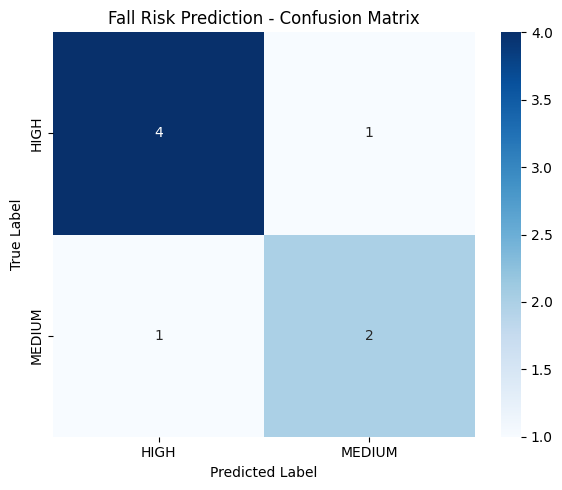

In [ ]:

# ============================================================
# 32. CONFUSION MATRIX FOR FALL RISK PREDICTION
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test_risk, risk_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=risk_label_encoder.classes_,
    yticklabels=risk_label_encoder.classes_
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Fall Risk Prediction - Confusion Matrix")
plt.tight_layout()
plt.savefig(os.path.join(RISK_FIGURE_DIR, "fall_risk_confusion_matrix.png"), dpi=300)
plt.show()


,feature,importance_mean,importance_std
73,total_tug_time,0.200559,0.086555
72,duration_STTS,0.155242,0.071577
0,skel_emb_000,0.000000,0.000000
3,skel_emb_003,0.000000,0.000000
4,skel_emb_004,0.000000,0.000000
1,skel_emb_001,0.000000,0.000000
2,skel_emb_002,0.000000,0.000000
7,skel_emb_007,0.000000,0.000000
8,skel_emb_008,0.000000,0.000000
9,skel_emb_009,0.000000,0.000000


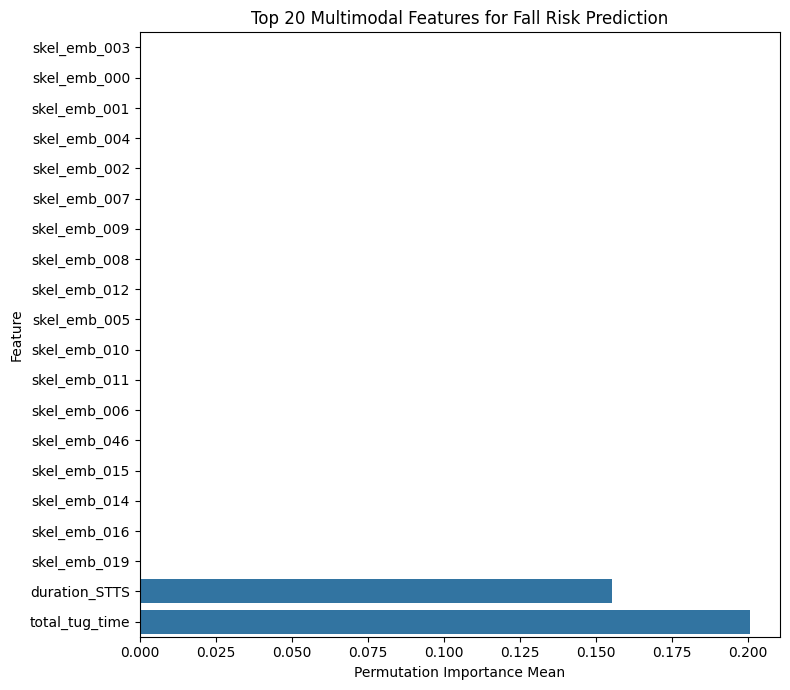

In [ ]:

# ============================================================
# 33. OPTIONAL FEATURE IMPORTANCE USING PERMUTATION IMPORTANCE
# ============================================================

from sklearn.inspection import permutation_importance
from sklearn.ensemble import RandomForestClassifier

# Permutation importance dengan RandomForest sebagai model interpretatif tambahan.
rf_risk = RandomForestClassifier(
    n_estimators=300,
    random_state=RANDOM_STATE,
    class_weight="balanced_subsample"
)
rf_risk.fit(X_train_risk, y_train_risk)

perm_result = permutation_importance(
    rf_risk,
    X_test_risk,
    y_test_risk,
    n_repeats=20,
    random_state=RANDOM_STATE,
    scoring="f1_weighted"
)

importance_df = pd.DataFrame({
    "feature": feature_cols,
    "importance_mean": perm_result.importances_mean,
    "importance_std": perm_result.importances_std
}).sort_values("importance_mean", ascending=False)

display(importance_df.head(30))
importance_df.to_csv(os.path.join(RISK_TABLE_DIR, "fall_risk_feature_importance.csv"), index=False)

plt.figure(figsize=(8, 7))
top_importance = importance_df.head(20).sort_values("importance_mean", ascending=True)
sns.barplot(data=top_importance, x="importance_mean", y="feature")
plt.xlabel("Permutation Importance Mean")
plt.ylabel("Feature")
plt.title("Top 20 Multimodal Features for Fall Risk Prediction")
plt.tight_layout()
plt.savefig(os.path.join(RISK_FIGURE_DIR, "fall_risk_feature_importance_top20.png"), dpi=300)
plt.show()

,feature,importance_mean,importance_std
73,total_tug_time,0.200559,0.086555
72,duration_STTS,0.155242,0.071577
0,skel_emb_000,0.000000,0.000000
3,skel_emb_003,0.000000,0.000000
4,skel_emb_004,0.000000,0.000000
1,skel_emb_001,0.000000,0.000000
2,skel_emb_002,0.000000,0.000000
7,skel_emb_007,0.000000,0.000000
8,skel_emb_008,0.000000,0.000000
9,skel_emb_009,0.000000,0.000000


Permutation Importance Summary - All Features
Total features                 : 79
Features with importance > 0   : 2
Features with importance == 0  : 74
Features with importance < 0   : 3


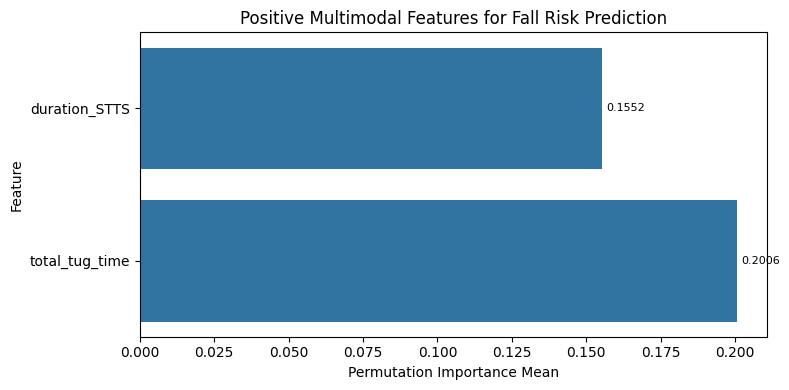

,feature,importance_mean,importance_std
69,duration_WO,0.141710,0.132915
71,duration_WI,0.106340,0.093728
72,duration_STTS,0.106340,0.093728
70,duration_TR,0.087273,0.071258
5,skel_emb_005,0.080000,0.072363
7,skel_emb_007,0.028371,0.084704
12,skel_emb_012,0.000000,0.000000
6,skel_emb_006,0.000000,0.000000
11,skel_emb_011,0.000000,0.000000
10,skel_emb_010,0.000000,0.000000


Permutation Importance Summary - Without total_tug_time
Total features                 : 78
Features with importance > 0   : 6
Features with importance == 0  : 56
Features with importance < 0   : 16


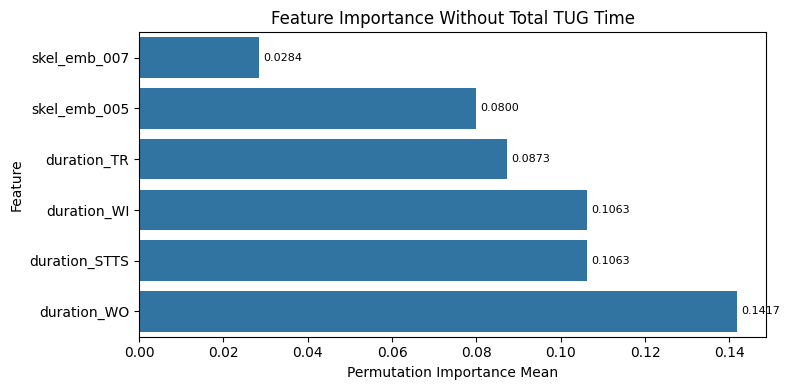

In [ ]:
# ============================================================
# 33. OPTIONAL FEATURE IMPORTANCE USING PERMUTATION IMPORTANCE
# ============================================================

from sklearn.inspection import permutation_importance
from sklearn.ensemble import RandomForestClassifier

# ============================================================
# A. PERMUTATION IMPORTANCE - ALL FEATURES
# ============================================================

rf_risk = RandomForestClassifier(
    n_estimators=300,
    random_state=RANDOM_STATE,
    class_weight="balanced_subsample"
)

rf_risk.fit(
    X_train_risk,
    y_train_risk
)

perm_result = permutation_importance(
    rf_risk,
    X_test_risk,
    y_test_risk,
    n_repeats=20,
    random_state=RANDOM_STATE,
    scoring="f1_weighted"
)

importance_df = pd.DataFrame({
    "feature": feature_cols,
    "importance_mean": perm_result.importances_mean,
    "importance_std": perm_result.importances_std
}).sort_values(
    "importance_mean",
    ascending=False
)

display(importance_df.head(40))

print("=" * 60)
print("Permutation Importance Summary - All Features")
print("=" * 60)
print("Total features                 :", len(importance_df))
print("Features with importance > 0   :", (importance_df["importance_mean"] > 0).sum())
print("Features with importance == 0  :", (importance_df["importance_mean"] == 0).sum())
print("Features with importance < 0   :", (importance_df["importance_mean"] < 0).sum())

importance_df.to_csv(
    os.path.join(
        RISK_TABLE_DIR,
        "fall_risk_feature_importance_all_features.csv"
    ),
    index=False
)

# ============================================================
# B. PLOT ONLY POSITIVE FEATURES
# ============================================================

positive_importance = (
    importance_df[importance_df["importance_mean"] > 0]
    .head(20)
    .sort_values("importance_mean", ascending=True)
)

if len(positive_importance) > 0:

    plt.figure(figsize=(8, max(4, 0.35 * len(positive_importance))))

    ax = sns.barplot(
        data=positive_importance,
        x="importance_mean",
        y="feature"
    )

    # Tambahkan nilai di ujung bar
    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.4f",
            padding=3,
            fontsize=8
        )

    plt.xlabel("Permutation Importance Mean")
    plt.ylabel("Feature")
    plt.title("Positive Multimodal Features for Fall Risk Prediction")
    plt.tight_layout()

    plt.savefig(
        os.path.join(
            RISK_FIGURE_DIR,
            "fall_risk_feature_importance_positive_features.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

else:
    print("Tidak ada feature dengan permutation importance positif.")

# ============================================================
# C. PERMUTATION IMPORTANCE WITHOUT total_tug_time
# ============================================================

feature_cols_no_total = [
    col for col in feature_cols
    if col != "total_tug_time"
]

X_train_risk_no_total = pd.DataFrame(
    X_train_risk,
    columns=feature_cols
)[feature_cols_no_total]

X_test_risk_no_total = pd.DataFrame(
    X_test_risk,
    columns=feature_cols
)[feature_cols_no_total]

rf_risk_no_total = RandomForestClassifier(
    n_estimators=300,
    random_state=RANDOM_STATE,
    class_weight="balanced_subsample"
)

rf_risk_no_total.fit(
    X_train_risk_no_total,
    y_train_risk
)

perm_result_no_total = permutation_importance(
    rf_risk_no_total,
    X_test_risk_no_total,
    y_test_risk,
    n_repeats=20,
    random_state=RANDOM_STATE,
    scoring="f1_weighted"
)

importance_no_total_df = pd.DataFrame({
    "feature": feature_cols_no_total,
    "importance_mean": perm_result_no_total.importances_mean,
    "importance_std": perm_result_no_total.importances_std
}).sort_values(
    "importance_mean",
    ascending=False
)

display(importance_no_total_df.head(40))

print("=" * 60)
print("Permutation Importance Summary - Without total_tug_time")
print("=" * 60)
print("Total features                 :", len(importance_no_total_df))
print("Features with importance > 0   :", (importance_no_total_df["importance_mean"] > 0).sum())
print("Features with importance == 0  :", (importance_no_total_df["importance_mean"] == 0).sum())
print("Features with importance < 0   :", (importance_no_total_df["importance_mean"] < 0).sum())

importance_no_total_df.to_csv(
    os.path.join(
        RISK_TABLE_DIR,
        "fall_risk_feature_importance_without_total_tug_time.csv"
    ),
    index=False
)

# ============================================================
# D. PLOT WITHOUT total_tug_time
# ============================================================

positive_no_total = (
    importance_no_total_df[importance_no_total_df["importance_mean"] > 0]
    .head(20)
    .sort_values("importance_mean", ascending=True)
)

if len(positive_no_total) > 0:

    plt.figure(figsize=(8, max(4, 0.35 * len(positive_no_total))))

    ax = sns.barplot(
        data=positive_no_total,
        x="importance_mean",
        y="feature"
    )

    # Tambahkan nilai di ujung bar
    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.4f",
            padding=3,
            fontsize=8
        )

    plt.xlabel("Permutation Importance Mean")
    plt.ylabel("Feature")
    plt.title("Feature Importance Without Total TUG Time")
    plt.tight_layout()

    plt.savefig(
        os.path.join(
            RISK_FIGURE_DIR,
            "fall_risk_feature_importance_without_total_tug_time.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

else:
    print("Tidak ada feature positif setelah total_tug_time dihapus.")

In [ ]:
# ============================================================
# CEK SEMUA MODEL KERAS YANG ADA - SAFE VERSION
# ============================================================

import tensorflow as tf

print("=" * 60)
print("TensorFlow/Keras Models")
print("=" * 60)

keras_models = []

for name, value in list(globals().items()):
    if isinstance(value, tf.keras.Model):
        keras_models.append(name)

if len(keras_models) == 0:
    print("Tidak ada model Keras yang ditemukan.")
else:
    for name in keras_models:
        print(name)

TensorFlow/Keras Models
model
best_model
skeleton_only_model
best_skeleton_only_model
attention_model
best_attention_model
embedding_model
risk_model


SHAP ANALYSIS FOR MULTIMODAL FALL RISK MODEL
Background samples : (22, 79)
Test samples       : (8, 79)
Number of features : 79

Using DeepExplainer...
SHAP 3D array detected.
Visualizing class index: 0
Final SHAP plot shape: (8, 79)


,Feature,MeanAbsSHAP
56,skel_emb_056,0.041949
55,skel_emb_055,0.035237
19,skel_emb_019,0.033818
20,skel_emb_020,0.032196
65,humidity,0.031441
18,skel_emb_018,0.030547
0,skel_emb_000,0.030182
45,skel_emb_045,0.025293
66,light_intensity,0.021865
68,duration_STS,0.021803


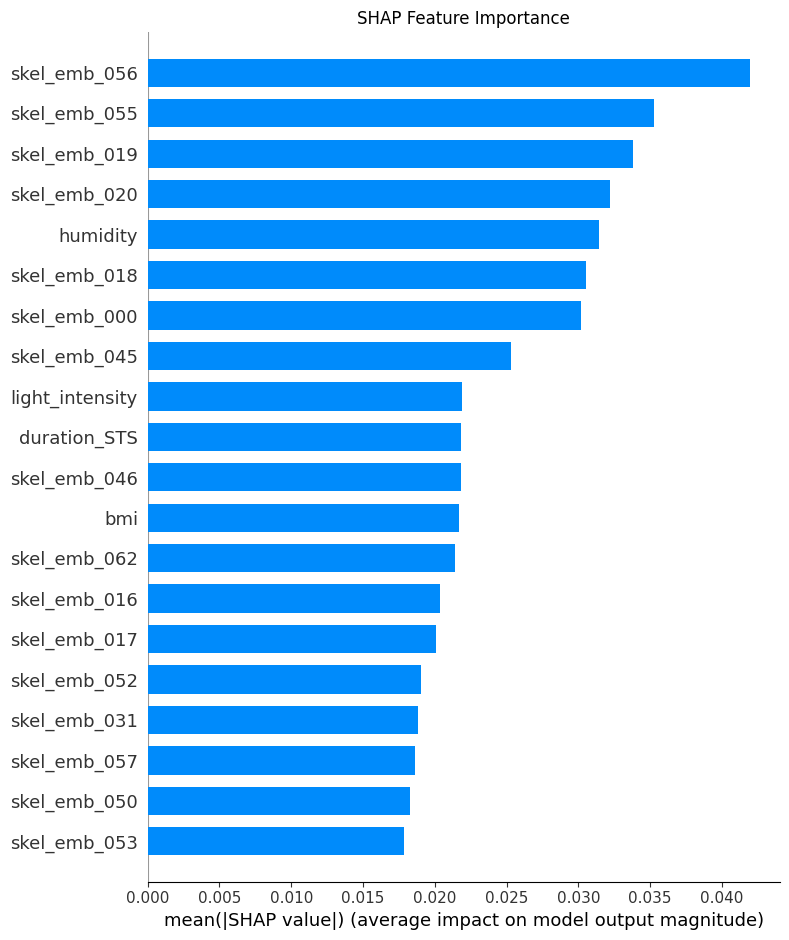

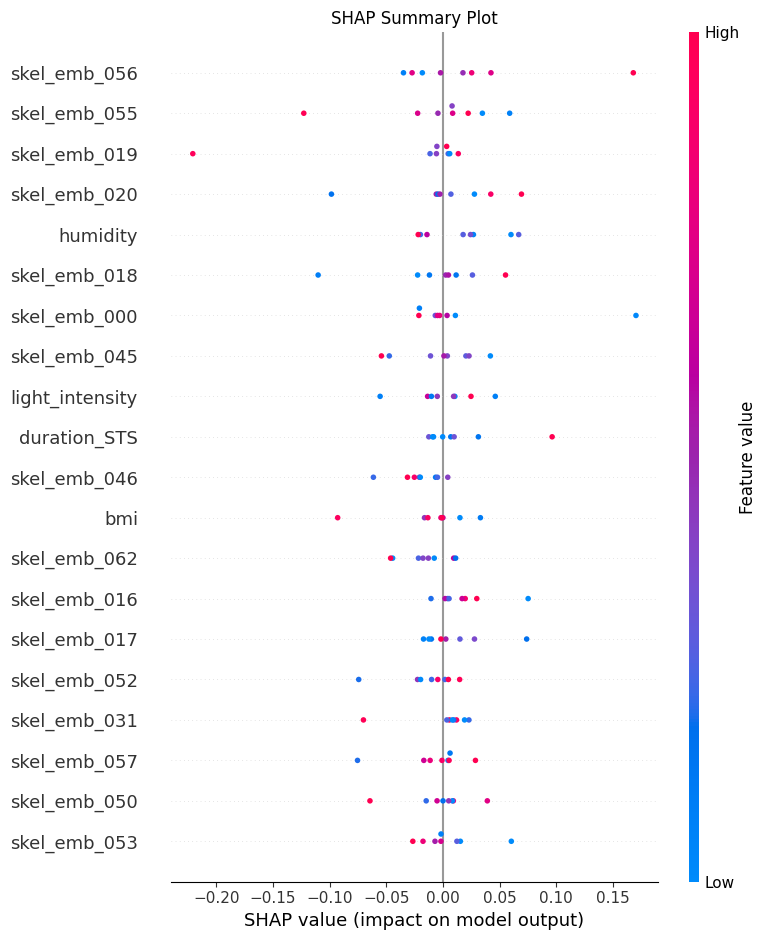

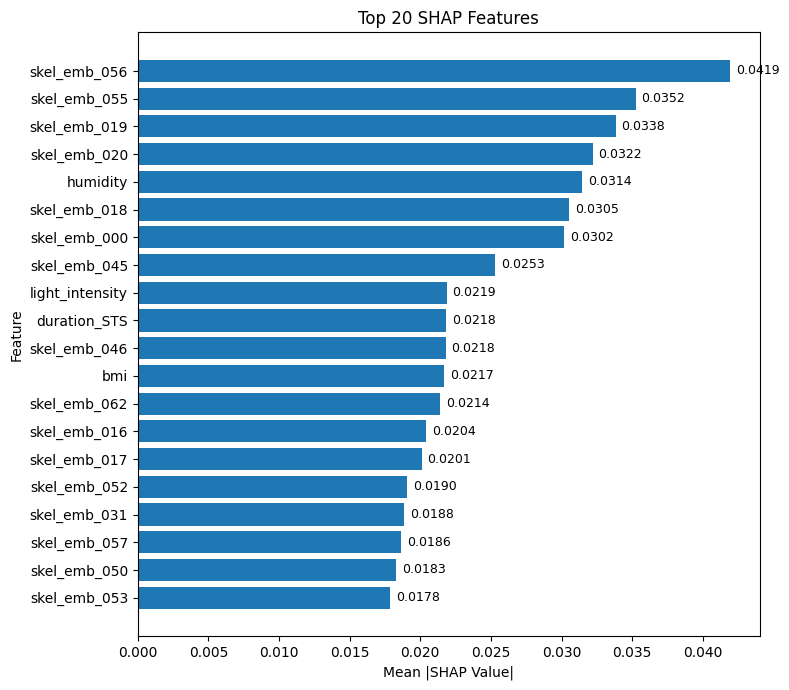


Top 20 Features


,Feature,MeanAbsSHAP
56,skel_emb_056,0.041949
55,skel_emb_055,0.035237
19,skel_emb_019,0.033818
20,skel_emb_020,0.032196
65,humidity,0.031441
18,skel_emb_018,0.030547
0,skel_emb_000,0.030182
45,skel_emb_045,0.025293
66,light_intensity,0.021865
68,duration_STS,0.021803


SHAP Analysis Completed


In [ ]:
# ============================================================
# STEP 33. SHAP ANALYSIS FOR MULTIMODAL FALL RISK MODEL
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

# Gunakan model Fall Risk Prediction yang tersedia
fall_risk_model = risk_model

print("=" * 70)
print("SHAP ANALYSIS FOR MULTIMODAL FALL RISK MODEL")
print("=" * 70)

# ============================================================
# CHECK VARIABLES
# ============================================================

required_vars = [
    "fall_risk_model",
    "X_train_risk",
    "X_test_risk",
    "feature_cols",
    "RISK_FIGURE_DIR"
]

for var in required_vars:
    if var not in globals():
        raise NameError(f"Variabel '{var}' belum tersedia.")

# Pastikan data berbentuk numpy array
X_train_shap = np.asarray(X_train_risk)
X_test_shap = np.asarray(X_test_risk)

# ============================================================
# BACKGROUND AND TEST SAMPLES
# ============================================================

background_size = min(100, len(X_train_shap))
test_size = min(100, len(X_test_shap))

background = X_train_shap[:background_size]
test_sample = X_test_shap[:test_size]

print(f"Background samples : {background.shape}")
print(f"Test samples       : {test_sample.shape}")
print(f"Number of features : {len(feature_cols)}")

# ============================================================
# SHAP EXPLAINER
# ============================================================

try:
    print("\nUsing DeepExplainer...")

    explainer = shap.DeepExplainer(
        fall_risk_model,
        background
    )

    shap_values = explainer.shap_values(test_sample)

except Exception as e:
    print("\nDeepExplainer not supported.")
    print("Reason:", e)
    print("Switching to KernelExplainer...\n")

    explainer = shap.KernelExplainer(
        fall_risk_model.predict,
        background
    )

    shap_values = explainer.shap_values(
        test_sample,
        nsamples=100
    )

# ============================================================
# HANDLE SHAP OUTPUT SHAPE - SAFE VERSION
# ============================================================

if isinstance(shap_values, list):
    shap_array = np.array(shap_values)

    # Format umum:
    # list[class] -> array dengan shape (class, samples, features)
    if shap_array.ndim == 3:
        mean_abs_per_class = np.mean(
            np.abs(shap_array),
            axis=(1, 2)
        )

        best_class = int(np.argmax(mean_abs_per_class))
        shap_plot = shap_array[best_class]

        print(f"SHAP list detected.")
        print(f"Visualizing class index: {best_class}")

    elif shap_array.ndim == 4:
        # Kadang output menjadi (class, samples, features, output_dim)
        shap_array = np.squeeze(shap_array)

        if shap_array.ndim == 3:
            mean_abs_per_class = np.mean(
                np.abs(shap_array),
                axis=(1, 2)
            )

            best_class = int(np.argmax(mean_abs_per_class))
            shap_plot = shap_array[best_class]

            print(f"SHAP squeezed list detected.")
            print(f"Visualizing class index: {best_class}")
        else:
            raise ValueError(f"Unexpected SHAP shape after squeeze: {shap_array.shape}")

    else:
        shap_plot = shap_values[0]

else:
    shap_array = np.array(shap_values)

    # Format: (samples, features, classes)
    if shap_array.ndim == 3:
        mean_abs_per_class = np.mean(
            np.abs(shap_array),
            axis=(0, 1)
        )

        best_class = int(np.argmax(mean_abs_per_class))
        shap_plot = shap_array[:, :, best_class]

        print(f"SHAP 3D array detected.")
        print(f"Visualizing class index: {best_class}")

    # Format: (samples, features)
    elif shap_array.ndim == 2:
        shap_plot = shap_array

    # Format tidak umum, coba squeeze
    else:
        shap_array = np.squeeze(shap_array)

        if shap_array.ndim == 2:
            shap_plot = shap_array

        elif shap_array.ndim == 3:
            mean_abs_per_class = np.mean(
                np.abs(shap_array),
                axis=(0, 1)
            )

            best_class = int(np.argmax(mean_abs_per_class))
            shap_plot = shap_array[:, :, best_class]

            print(f"SHAP squeezed 3D array detected.")
            print(f"Visualizing class index: {best_class}")

        else:
            raise ValueError(f"Unexpected SHAP shape: {shap_array.shape}")

# Pastikan shap_plot 2D: samples x features
shap_plot = np.asarray(shap_plot)
shap_plot = np.squeeze(shap_plot)

print("Final SHAP plot shape:", shap_plot.shape)

if shap_plot.ndim != 2:
    raise ValueError(
        f"shap_plot masih bukan 2D. Shape saat ini: {shap_plot.shape}"
    )

if shap_plot.shape[1] != len(feature_cols):
    raise ValueError(
        f"Jumlah fitur tidak cocok. "
        f"shap_plot memiliki {shap_plot.shape[1]} fitur, "
        f"sedangkan feature_cols memiliki {len(feature_cols)} fitur."
    )

# ============================================================
# FEATURE IMPORTANCE TABLE
# ============================================================

mean_abs_shap = np.mean(
    np.abs(shap_plot),
    axis=0
)

mean_abs_shap = np.asarray(mean_abs_shap).reshape(-1)

importance_df = pd.DataFrame({
    "Feature": feature_cols,
    "MeanAbsSHAP": mean_abs_shap
}).sort_values(
    "MeanAbsSHAP",
    ascending=False
)

display(importance_df.head(30))

importance_df.to_csv(
    os.path.join(
        RISK_FIGURE_DIR,
        "shap_feature_importance.csv"
    ),
    index=False
)

# ============================================================
# SHAP BAR PLOT
# ============================================================

plt.figure(figsize=(9, 8))

shap.summary_plot(
    shap_plot,
    test_sample,
    feature_names=feature_cols,
    plot_type="bar",
    show=False
)

plt.title("SHAP Feature Importance")
plt.tight_layout()

plt.savefig(
    os.path.join(
        RISK_FIGURE_DIR,
        "shap_bar_plot.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# SHAP SUMMARY PLOT
# ============================================================

plt.figure(figsize=(10, 8))

shap.summary_plot(
    shap_plot,
    test_sample,
    feature_names=feature_cols,
    show=False
)

plt.title("SHAP Summary Plot")
plt.tight_layout()

plt.savefig(
    os.path.join(
        RISK_FIGURE_DIR,
        "shap_summary_plot.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# TOP 20 FEATURES
# ============================================================

top20 = importance_df.head(20)

plt.figure(figsize=(8, 7))

bars = plt.barh(
    top20["Feature"][::-1],
    top20["MeanAbsSHAP"][::-1]
)

for bar in bars:
    width = bar.get_width()

    plt.text(
        width + (top20["MeanAbsSHAP"].max() * 0.01),
        bar.get_y() + bar.get_height() / 2,
        f"{width:.4f}",
        va="center",
        fontsize=9
    )

plt.xlabel("Mean |SHAP Value|")
plt.ylabel("Feature")
plt.title("Top 20 SHAP Features")
plt.tight_layout()

plt.savefig(
    os.path.join(
        RISK_FIGURE_DIR,
        "top20_shap_features.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nTop 20 Features")
display(top20)

print("=" * 70)
print("SHAP Analysis Completed")
print("=" * 70)

In [ ]:
# ============================================================
# FILTER FEATURES FOR INTERPRETABLE SHAP VISUALIZATION
# ============================================================

# Tetap gunakan seluruh feature pada model,
# tetapi sembunyikan skeleton embedding pada visualisasi SHAP.

display_idx = [
    i for i, f in enumerate(feature_cols)
    if not f.startswith("skel_emb_")
]

display_feature_cols = [
    feature_cols[i]
    for i in display_idx
]

# SHAP hanya untuk visualisasi
shap_plot_display = shap_plot[:, display_idx]

# Data input hanya untuk visualisasi
test_sample_display = test_sample[:, display_idx]

# Feature importance yang akan ditampilkan
mean_abs_shap = np.mean(
    np.abs(shap_plot_display),
    axis=0
)

importance_df = pd.DataFrame({
    "Feature": display_feature_cols,
    "MeanAbsSHAP": mean_abs_shap
}).sort_values(
    "MeanAbsSHAP",
    ascending=False
)

display(importance_df.head(30))

importance_df.to_csv(
    os.path.join(
        RISK_FIGURE_DIR,
        "shap_feature_importance.csv"
    ),
    index=False
)

,Feature,MeanAbsSHAP
1,humidity,0.031441
2,light_intensity,0.021865
4,duration_STS,0.021803
11,bmi,0.021656
7,duration_WI,0.017513
14,mean_heart_rate,0.012588
10,age,0.012477
0,temperature,0.012382
13,mean_spo2,0.012016
3,pressure,0.011177


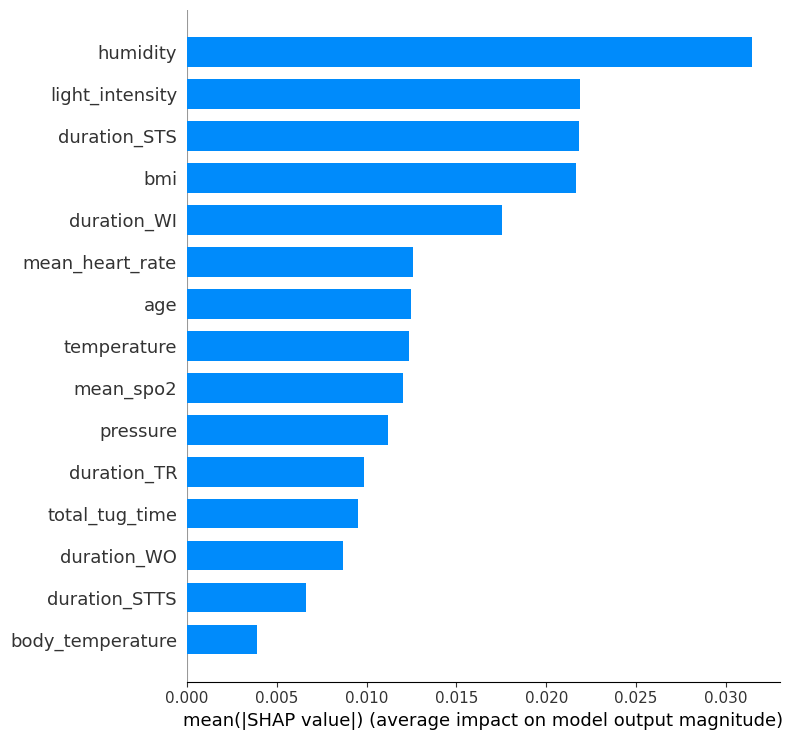

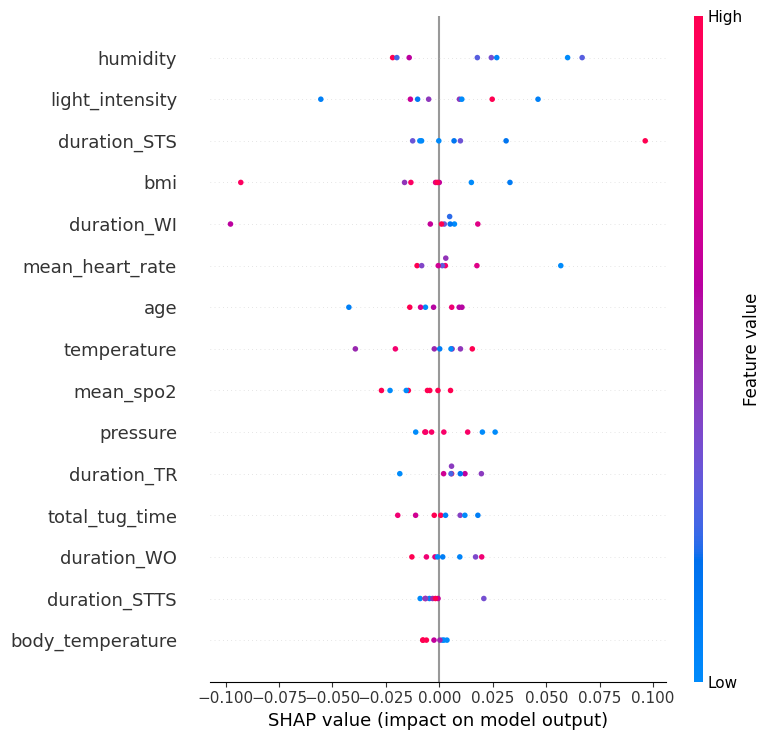

In [ ]:
# ============================================================
# SHAP BAR PLOT
# ============================================================

plt.figure(figsize=(9,8))

shap.summary_plot(
    shap_plot_display,
    test_sample_display,
    feature_names=display_feature_cols,
    plot_type="bar",
    show=False
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        RISK_FIGURE_DIR,
        "shap_bar_plot.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# SHAP SUMMARY PLOT
# ============================================================

plt.figure(figsize=(10,8))

shap.summary_plot(
    shap_plot_display,
    test_sample_display,
    feature_names=display_feature_cols,
    show=False
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        RISK_FIGURE_DIR,
        "shap_summary_plot.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:

# ============================================================
# 34. MODEL EXPORT: .keras, .tflite, .onnx
# ============================================================

KERAS_EXPORT_PATH = os.path.join(RISK_MODEL_DIR, "fall_risk_model_export.keras")
TFLITE_EXPORT_PATH = os.path.join(RISK_MODEL_DIR, "fall_risk_model_export.tflite")
ONNX_EXPORT_PATH = os.path.join(RISK_MODEL_DIR, "fall_risk_model_export.onnx")

# 1. Keras
risk_model.save(KERAS_EXPORT_PATH)
print("Saved Keras model:", KERAS_EXPORT_PATH)

# 2. TensorFlow Lite
converter = tf.lite.TFLiteConverter.from_keras_model(risk_model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()

with open(TFLITE_EXPORT_PATH, "wb") as f:
    f.write(tflite_model)
print("Saved TFLite model:", TFLITE_EXPORT_PATH)

# 3. ONNX
# Jika belum tersedia di Colab, jalankan:
# !pip install -q tf2onnx
try:
    import tf2onnx

    input_signature = [
        tf.TensorSpec(
            shape=(None, X_train_risk.shape[1]),
            dtype=tf.float32,
            name="multimodal_risk_input"
        )
    ]

    onnx_model, _ = tf2onnx.convert.from_keras(
        risk_model,
        input_signature=input_signature,
        opset=13,
        output_path=ONNX_EXPORT_PATH
    )
    print("Saved ONNX model:", ONNX_EXPORT_PATH)

except Exception as e:
    print("ONNX export belum berhasil.")
    print("Penyebab:", repr(e))
    print("Solusi di Colab: jalankan '!pip install -q tf2onnx', lalu ulangi cell export ini.")

print("=" * 70)
print("MODEL EXPORT COMPLETED")
print("=" * 70)
print("Files in model directory:")
for file in sorted(os.listdir(RISK_MODEL_DIR)):
    print("-", file)

Saved Keras model: /content/drive/MyDrive/DATASET-TUG-CONTEXT/Results/Multimodal_Fall_Risk/Models/fall_risk_model_export.keras
Saved artifact at '/tmp/tmp0whwcwvn'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 79), dtype=tf.float32, name='multimodal_risk_input')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  132880682586320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132880682586704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132880682586128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132880682588240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132880682588048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132880682587472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132880682588624: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132880682588432: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132880682585360: TensorSpec

In [ ]:
# ============================================================
# CEK LAYER best_attention_model
# ============================================================

best_attention_model.summary()

print("\nLayer names:")
for layer in best_attention_model.layers:
    print(layer.name)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ skeleton_input      │ (None, 30, 66)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 30, 64)    │     12,736 │ skeleton_input[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 30, 64)    │        256 │ conv1d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 15, 64)    │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 15, 128)   │     24,704 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 15, 128)   │        512 │ conv1d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ context_input       │ (None, 4)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 128)       │     98,816 │ batch_normalizat… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ context_feature     │ (None, 32)        │        160 │ context_input[0]… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 32)        │          0 │ context_feature[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ skeleton_feature    │ (None, 64)        │      8,256 │ dropout[0][0]     │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_weight    │ (None, 64)        │      2,112 │ dropout_1[0][0]   │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attended_skeleton   │ (None, 64)        │          0 │ skeleton_feature… │
│ (Multiply)          │                   │            │ attention_weight… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_fusion    │ (None, 96)        │          0 │ attended_skeleto… │
│ (Concatenate)       │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      6,208 │ attention_fusion… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │      2,080 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ phase_output        │ (None, 5)         │        165 │ dense_1[0][0]     │
│ (Dense)             │                   │            │                 

 Total params: 467,249 (1.78 MB)

 Trainable params: 155,621 (607.89 KB)

 Non-trainable params: 384 (1.50 KB)

 Optimizer params: 311,244 (1.19 MB)


Layer names:
skeleton_input
conv1d
batch_normalization
max_pooling1d
conv1d_1
batch_normalization_1
context_input
bidirectional
context_feature
dropout
dropout_1
skeleton_feature
attention_weight
attended_skeleton
attention_fusion
dense
dropout_2
dense_1
phase_output


In [ ]:
# ============================================================
# CEK MODEL KERAS YANG ADA DI MEMORY
# ============================================================

import tensorflow as tf

print("=" * 60)
print("Keras Models in Memory")
print("=" * 60)

for name, value in list(globals().items()):
    if isinstance(value, tf.keras.Model):
        print(f"{name:30s} | input: {len(value.inputs)} | output: {value.output_shape}")

Keras Models in Memory
model                          | input: 2 | output: (None, 5)
best_model                     | input: 2 | output: (None, 5)
skeleton_only_model            | input: 1 | output: (None, 5)
best_skeleton_only_model       | input: 1 | output: (None, 5)
attention_model                | input: 2 | output: (None, 5)
best_attention_model           | input: 2 | output: (None, 5)
embedding_model                | input: 2 | output: (None, 64)
risk_model                     | input: 1 | output: (None, 2)
fall_risk_model                | input: 1 | output: (None, 2)


In [ ]:
# ============================================================
# STEP 34. SAVE INFERENCE PACKAGE FOR GRADIO APP
# ============================================================

import os
import json
import joblib
import numpy as np
import tensorflow as tf
from sklearn.preprocessing import LabelEncoder

SAVE_DIR = "/content/drive/MyDrive/DATASET-TUG-CONTEXT/trained_model"
os.makedirs(SAVE_DIR, exist_ok=True)

# ============================================================
# 1. SAVE MODELS
# ============================================================

best_attention_model.save(
    os.path.join(SAVE_DIR, "phase_classifier_attention_fusion.keras")
)

embedding_model.save(
    os.path.join(SAVE_DIR, "skeleton_embedding_extractor.keras")
)

fall_risk_model.save(
    os.path.join(SAVE_DIR, "fall_risk_model.keras")
)

# ============================================================
# 2. SAVE SCALERS
# ============================================================

joblib.dump(
    skeleton_scaler,
    os.path.join(SAVE_DIR, "skeleton_scaler.pkl")
)

joblib.dump(
    context_scaler,
    os.path.join(SAVE_DIR, "context_scaler.pkl")
)

joblib.dump(
    risk_scaler,
    os.path.join(SAVE_DIR, "risk_scaler.pkl")
)

# ============================================================
# 3. SAVE PHASE LABEL ENCODER
# ============================================================

joblib.dump(
    label_encoder,
    os.path.join(SAVE_DIR, "phase_label_encoder.pkl")
)

# ============================================================
# 4. CREATE OR SAVE RISK LABEL ENCODER
# ============================================================

if "risk_encoder" in globals():
    final_risk_encoder = risk_encoder

elif "risk_label_encoder" in globals():
    final_risk_encoder = risk_label_encoder

else:
    final_risk_encoder = LabelEncoder()

    # Sesuaikan dengan label risk model Anda
    # Karena output risk_model = (None, 2), berarti binary classification
    final_risk_encoder.fit([
        "Low Risk",
        "High Risk"
    ])

joblib.dump(
    final_risk_encoder,
    os.path.join(SAVE_DIR, "risk_label_encoder.pkl")
)

# ============================================================
# 5. SAVE CONFIG
# ============================================================

config = {
    "window_size": 30,
    "step_size": 15,

    "selected_landmarks": [
        11, 12, 13, 14, 15, 16,
        17, 18, 19, 20, 21, 22,
        23, 24, 25, 26, 27, 28,
        29, 30, 31, 32
    ],

    "duration_cols": [
        "duration_STS",
        "duration_WO",
        "duration_TR",
        "duration_WI",
        "duration_STTS",
        "total_tug_time"
    ],

    "context_cols": [
        "temperature",
        "humidity",
        "light_intensity",
        "pressure"
    ],

    "physio_cols": [
        "age",
        "bmi",
        "body_temperature",
        "mean_spo2",
        "mean_heart_rate"
    ],

    "phase_model": "phase_classifier_attention_fusion.keras",
    "embedding_model": "skeleton_embedding_extractor.keras",
    "risk_model": "fall_risk_model.keras",

    "embedding_dim": int(embedding_model.output_shape[-1]),
    "risk_output_dim": int(fall_risk_model.output_shape[-1])
}

with open(
    os.path.join(SAVE_DIR, "inference_config.json"),
    "w"
) as f:
    json.dump(config, f, indent=4)

print("=" * 70)
print("INFERENCE PACKAGE SAVED")
print("=" * 70)

print("Saved directory:")
print(SAVE_DIR)

print("\nFiles:")
for file in sorted(os.listdir(SAVE_DIR)):
    print("-", file)

INFERENCE PACKAGE SAVED
Saved directory:
/content/drive/MyDrive/DATASET-TUG-CONTEXT/trained_model

Files:
- context_scaler.pkl
- fall_risk_model.keras
- inference_config.json
- phase_classifier_attention_fusion.keras
- phase_label_encoder.pkl
- risk_label_encoder.pkl
- risk_scaler.pkl
- skeleton_embedding_extractor.keras
- skeleton_scaler.pkl


In [ ]:
best_attention_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ skeleton_input      │ (None, 30, 66)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 30, 64)    │     12,736 │ skeleton_input[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 30, 64)    │        256 │ conv1d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 15, 64)    │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 15, 128)   │     24,704 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 15, 128)   │        512 │ conv1d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ context_input       │ (None, 4)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 128)       │     98,816 │ batch_normalizat… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ context_feature     │ (None, 32)        │        160 │ context_input[0]… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 32)        │          0 │ context_feature[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ skeleton_feature    │ (None, 64)        │      8,256 │ dropout[0][0]     │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_weight    │ (None, 64)        │      2,112 │ dropout_1[0][0]   │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attended_skeleton   │ (None, 64)        │          0 │ skeleton_feature… │
│ (Multiply)          │                   │            │ attention_weight… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_fusion    │ (None, 96)        │          0 │ attended_skeleto… │
│ (Concatenate)       │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      6,208 │ attention_fusion… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │      2,080 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ phase_output        │ (None, 5)         │        165 │ dense_1[0][0]     │
│ (Dense)             │                   │            │                 

 Total params: 467,249 (1.78 MB)

 Trainable params: 155,621 (607.89 KB)

 Non-trainable params: 384 (1.50 KB)

 Optimizer params: 311,244 (1.19 MB)


## Catatan Akhir Perapian Notebook

Bagian akhir notebook lama yang berisi ekstraksi durasi, labeling risiko, visualisasi, korelasi, dan SHAP yang berulang telah diganti dengan pipeline tunggal yang lebih konsisten. Struktur akhir sekarang sudah sesuai dengan rancangan penelitian:

1. **Skeleton Preprocessing**: Raw → Mid-Hip Centering → 3D Shoulder Width Normalization  
2. **Windowing**  
3. **CNN-BiLSTM Phase Classification**  
4. **Phase Duration Extraction**  
5. **Skeleton + Context + Duration + Physiological Data Fusion**  
6. **Fall Risk Prediction Model**  
7. **Evaluation**  
8. **Model Export**: `.keras`, `.tflite`, `.onnx`
